# Compute Level vs. Accuracy, Latency and Reasoning Efficiency

**Goal.** Quantify how the *compute level* given to an LLM relates to (i) accuracy, (ii) elapsed time and (iii) token efficiency, using repeated samples of benchmark questions.

**How to use.** Set `DATA_PATH` and `SAVE_DIR` in the configuration cell and run all cells. Only the key figures (PNG) and tables (CSV) listed in `SAVE_ONLY` are written to `SAVE_DIR`, under a fixed, model-prefixed name (`<MODEL_NAME>__<section>_<topic>.png`), so re-running the notebook overwrites the previous files. To analyse several models, run the notebook once per model (see Appendix A) and compare the saved summaries.

**Storyline.** The sections follow the order in which the results are best explained: the answer first, then the evidence behind it, then the cost.

| # | Section | Question answered |
|---|---------|-------------------|
| 1 | Setup and data validation | What data do we have, and is it complete and balanced? |
| 2 | Realised compute | Do higher compute levels really make the model think more? |
| 3 | Headline | What is the overall relationship between compute and accuracy? |
| 4 | Per-benchmark behaviour | Does every benchmark follow the headline? |
| 5 | Robustness | Is the headline driven by a single benchmark? |
| 6 | Task types | Do MCQ and open-ended tasks scale differently? |
| 7 | Difficulty | Does compute help easy or hard questions more? |
| 8 | Diminishing returns | Where do additional levels stop paying off? |
| 9 | Truncation and response format | How much of the pattern is mechanical? |
| 10 | Repeated samples | Is it better to think longer or to sample more? |
| 11 | Cost | Latency, tokens per correct answer, accuracy per 1,000 tokens |
| 12 | Recommendation and limitations | Which level to run, and how far can the conclusions be trusted? |
| A | Appendix: several models | How do models compare? |

## 0. Methodology

* **Unit of analysis = question.** Each question is answered several times (`sample_index`) at each level and those samples are correlated. All intervals come from a **cluster bootstrap over questions** (percentile intervals).
* **One resample, used everywhere.** The bootstrap weights of every question are drawn once and reused by all estimates, so any difference between two quantities (levels, task types, aggregation schemes) is a valid *paired* difference.
* **No row-pooled averages.** Pooling rows lets large benchmarks dominate. Metrics are averaged over samples within a question, over questions within a benchmark, then over benchmarks with equal weight (per task type, then overall).
* **Same benchmarks and same questions at every level** for all level-to-level comparisons (the *primary* estimate). Every exclusion is counted and printed.
* **Headroom-aware effect size.** Benchmarks near the ceiling (GSM8K) and near the floor (AIME) cannot show the same gain in percentage points, so every gain is also reported as a **normalised gain** = (a_level - a_lowest) / (1 - a_lowest): the share of the headroom left at the lowest level that is recovered. Subtracting a chance level from both accuracies cancels out, so the same formula holds for MCQ.
* **Formal tests.** Level effects are tested on the ordinal level (trend), and differences between task types or difficulty tiers by a compute x group interaction in a logistic model with standard errors clustered on the question.
* **Multiple comparisons.** Per-benchmark and per-step claims are Holm-adjusted; the other intervals are descriptive.
* **Interpretation limits.** Benchmarks are a fixed set; compute level is observed, not randomised by us, so statements are associations unless the experiment itself was controlled.

In [100]:
# ============================ CONFIGURATION ============================
DATA_PATH = "../../data/raw/r1-llama8b/r1-llama8b_raw_results.csv"   # <-- SET THIS: .csv or .tsv
SAVE_DIR = "../../results/r1-llama8b/compute_level_analysis"                   # <-- SET THIS: folder for all figures (PNG) and tables (CSV); created if missing
MODEL_NAME = None             # shown in figure titles and used as file-name prefix; None = taken from the data file name

# ---- Optional settings (defaults are sensible) ----
PRESENT_MODE = False          # True = also export a 16:9, large-font, one-line-takeaway copy of every figure to SAVE_DIR/slides
COMPUTE_ORDER = None          # e.g. ["low", "medium", "high"]; None = infer the order automatically
TIER_ORDER = None             # e.g. ["easy", "medium", "hard"]; None = infer automatically
DIFFICULTY_SOURCE = "metadata"   # "metadata" = use the difficulty_tier column; "split_half" = build tiers from the pass rate of half of the samples and measure on the other half
TASK_TYPE_MAP = {             # benchmark -> task type; unlisted benchmarks use the task_type column, then the format inferred from `gold`
    "MMLU-Redux": "MCQ",
    "MMLU-Pro": "MCQ",
    "GPQA-Diamond": "MCQ",
    "GSM8K": "Open-ended",
    "MATH-full": "Open-ended",
    "AIME2025": "Open-ended",
    "LiveCodeBench-v6": "Open-ended",
    "IFEval": "Open-ended",
    "BFCL-v3-simple": "Open-ended",
}
SAVE_ONLY = {
    "01_setup",                     
    "02_realised_compute",          
    "11_latency",                   
    "03_headline",                  
    "05_leave_one_out",             
    "04_per_benchmark",             
    "06_task_types", "07_difficulty",
    "08_diminishing_returns",
    "09_truncation",
    "10_repeated_samples",
    "11_efficiency",
    "12_operating_points", "summary",
}
N_BOOT = 2000                 # bootstrap replicates (use ~200 for a quick draft)
CI_LEVEL = 0.95               # confidence level of all intervals (Holm-adjusted tests use alpha = 1 - CI_LEVEL)
SEED = 42                     # random seed
MISSING_CORRECT = "drop"      # rows whose is_correct cannot be read: "drop" (counted and reported) or "incorrect"
DROP_DUPLICATES = False       # True = keep only the first row of repeated (benchmark, question, level, sample) keys
MIN_QUESTIONS_PER_CELL = 20   # benchmark x level cells with fewer questions are flagged as low-n

In [101]:
# ----------------------------- Imports & style -----------------------------
import math
import re
import textwrap
import warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.text as mtext
import matplotlib.ticker as mticker
from IPython.display import display, Markdown

try:
    import statsmodels.formula.api as smf
    HAS_SM = True
except ImportError:
    HAS_SM = False
    print("statsmodels not installed: formal tests (trend, interaction) are skipped.")

warnings.filterwarnings("ignore", category=RuntimeWarning)   # nanmean of empty slices is expected for missing cells
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

PALETTE = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000", "#999999"]   # Okabe-Ito, colour-blind safe
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 9, "axes.prop_cycle": plt.cycler(color=PALETTE),
})

if SAVE_DIR in (None, "", "PATH/TO/SAVE/FIGURES"):
    raise ValueError("Set SAVE_DIR in the configuration cell.")
if MODEL_NAME in (None, ""):
    MODEL_NAME = re.sub(r"_raw_results$", "", Path(DATA_PATH).stem)
SAVE_PATH = Path(SAVE_DIR).expanduser()
SAVE_PATH.mkdir(parents=True, exist_ok=True)
SLIDE_PATH = SAVE_PATH / "slides"
print(f"Model: {MODEL_NAME} | outputs: {SAVE_PATH.resolve()}")


def md(text):
    """Render Markdown produced by code (data-driven 'Observed' notes)."""
    display(Markdown(text))


def _out(name, ext, folder=None):
    return (folder or SAVE_PATH) / f"{MODEL_NAME}__{name}.{ext}"      # fixed name: a re-run overwrites the old file


def save_table(df, name):
    """Write a table to SAVE_DIR as <MODEL_NAME>__<name>.csv (only if the name is in SAVE_ONLY)."""
    if name not in SAVE_ONLY:
        return
    out = _out(name, "csv")
    df.to_csv(out)
    print(f"Saved table: {out}")


def _slide_copy(fig, name, takeaway):
    """Export a 16:9 copy with larger fonts and a one-line takeaway title, then restore the figure."""
    SLIDE_PATH.mkdir(parents=True, exist_ok=True)
    size0 = fig.get_size_inches().copy()
    fonts = [(t, t.get_fontsize()) for t in fig.findobj(mtext.Text)]
    titles = [(ax, ax.get_title()) for ax in fig.axes]
    sup = getattr(fig, "_suptitle", None)
    sup0 = (sup.get_text(), sup.get_fontsize(), sup.get_fontweight()) if sup is not None else ("", 12, "bold")
    fig.set_size_inches(13.33, 7.5)
    for t, s in fonts:
        t.set_fontsize(s * 1.3)
    for ax, t in titles:
        ax.set_title(textwrap.fill(t, 34))
    fig.suptitle(f"{MODEL_NAME}: {takeaway}", fontsize=20, fontweight="bold")
    fig.tight_layout()
    fig.savefig(_out(name, "png", SLIDE_PATH), dpi=150, bbox_inches="tight")
    fig.set_size_inches(size0)
    for t, s in fonts:
        t.set_fontsize(s)
    for ax, t in titles:
        ax.set_title(t)
    fig.suptitle(sup0[0], fontsize=sup0[1], fontweight=sup0[2])
    fig.tight_layout()


def finish(fig, name, title, takeaway=None):
    """Add the model name to the title, show it, and save it (fixed name, overwrites) only if it is in SAVE_ONLY."""
    fig.suptitle(f"{MODEL_NAME} | {title}", fontsize=12, fontweight="bold")
    fig.tight_layout()
    if name in SAVE_ONLY:
        out = _out(name, "png")
        fig.savefig(out, dpi=150, bbox_inches="tight")
        print(f"Saved figure: {out}")
        if PRESENT_MODE:
            _slide_copy(fig, name, takeaway or title)
    plt.show()

Model: r1-llama8b | outputs: C:\Users\afath\Desktop\Orange Lab\test-time-compute-allocation\src\results\r1-llama8b\compute_level_analysis


## 1. Setup and data validation

A short sanity check of the file, then the benchmark x compute-level coverage, which is the main source of misleading aggregates if incomplete.

### 1.1 Load, clean and order the levels

In [102]:
# ------------------------------ Load -------------------------------------
path = Path(DATA_PATH).expanduser()
if not path.exists():
    raise FileNotFoundError(f"Dataset not found at '{path}'. Set DATA_PATH in the first cell.")

readers = {".csv": pd.read_csv, ".tsv": lambda p: pd.read_csv(p, sep="\t")}
if path.suffix.lower() not in readers:
    raise ValueError(f"Unsupported file type '{path.suffix}'. Supported: {sorted(readers)}")
raw = readers[path.suffix.lower()](path)
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns from '{path.name}'")

EXPECTED = ["question_id", "benchmark", "difficulty_tier", "task_type", "compute_level", "sample_index",
            "raw_model_output", "thinking_text", "gold", "is_correct", "tokens_used", "thinking_tokens",
            "output_tokens", "hit_response_marker", "latency_s", "was_truncated", "hit_marker_empty_output"]
REQUIRED = ["question_id", "benchmark", "compute_level", "is_correct"]   # the analysis cannot run without these

missing_required = [c for c in REQUIRED if c not in raw.columns]
if missing_required:
    raise KeyError(f"Required columns missing: {missing_required}. Found: {list(raw.columns)}")
missing_optional = [c for c in EXPECTED if c not in raw.columns]
if missing_optional:
    print("Optional columns absent (related analyses are simplified or skipped):", missing_optional)

Loaded 9,450 rows x 17 columns from 'r1-llama8b_raw_results.csv'


In [103]:
# --------------------------- Clean & standardise --------------------------
def to_float01(s):
    """Convert booleans / 'True'/'False' / 0/1 / yes/no to 1.0/0.0; unreadable values become NaN."""
    if s.dtype == bool:
        return s.astype(float)
    m = {"true": 1.0, "false": 0.0, "1": 1.0, "0": 0.0, "1.0": 1.0, "0.0": 0.0, "yes": 1.0, "no": 0.0, "t": 1.0, "f": 0.0}
    return s.astype(str).str.strip().str.lower().map(m).astype(float)


df = raw.copy()

# Text-derived diagnostics first, then the heavy text columns are dropped to save memory.
if "raw_model_output" in raw.columns:
    out_txt = raw["raw_model_output"]
    df["output_empty"] = (out_txt.isna() | out_txt.astype(str).str.strip().eq("")).astype(float)
else:
    df["output_empty"] = np.nan
df = df.drop(columns=[c for c in ["raw_model_output", "thinking_text"] if c in df.columns])

for c in ["benchmark", "task_type", "difficulty_tier"]:
    if c in df.columns:
        df[c] = df[c].astype("string").str.strip().replace("", pd.NA).fillna("unknown").astype(str)
    else:
        df[c] = "unknown"
df["question_id"] = df["question_id"].astype(str)
if "gold" not in df.columns:
    df["gold"] = np.nan

# Compute level: numeric if every value is numeric, otherwise a label
lv_num = pd.to_numeric(df["compute_level"], errors="coerce")
df["compute_level"] = lv_num if lv_num.notna().all() else df["compute_level"].astype("string").str.strip().astype(object)
n_lv_missing = int(df["compute_level"].isna().sum())
if n_lv_missing:
    print(f"Dropping {n_lv_missing:,} rows with missing compute_level.")
    df = df[df["compute_level"].notna()].copy()

for c in ["tokens_used", "thinking_tokens", "output_tokens", "latency_s"]:
    df[c] = pd.to_numeric(df[c], errors="coerce") if c in df.columns else np.nan
if df["tokens_used"].isna().all():
    df["tokens_used"] = df["thinking_tokens"] + df["output_tokens"]
for c in ["hit_response_marker", "was_truncated", "hit_marker_empty_output"]:
    df[c] = to_float01(df[c]) if c in df.columns else np.nan
df["correct"] = to_float01(df["is_correct"])

if "sample_index" not in df.columns:
    df["sample_index"] = df.groupby(["benchmark", "question_id", "compute_level"]).cumcount()
else:
    si = pd.to_numeric(df["sample_index"], errors="coerce")
    df["sample_index"] = si.fillna(df.groupby(["benchmark", "question_id", "compute_level"]).cumcount())

KEY = ["benchmark", "question_id", "compute_level", "sample_index"]
dup = df.duplicated(KEY, keep=False)
print(f"Duplicate-key rows: {int(dup.sum()):,}")
if DROP_DUPLICATES and dup.any():
    before = len(df)
    df = df.drop_duplicates(KEY, keep="first")
    print(f"  DROP_DUPLICATES=True -> removed {before - len(df):,} rows.")

n_unread = int(df["correct"].isna().sum())
print(f"Unreadable is_correct: {n_unread:,} ({n_unread / len(df):.2%}) -> policy '{MISSING_CORRECT}'.")
if MISSING_CORRECT == "incorrect":
    df["correct"] = df["correct"].fillna(0.0)
d = df[df["correct"].notna()].copy()          # analysis frame; `df` keeps everything for diagnostics
print(f"Analysis frame `d`: {len(d):,} rows.")


# ----------------------- Compute-level ordering ---------------------------
def resolve_level_order(frame):
    levels = frame["compute_level"].dropna().unique().tolist()
    if COMPUTE_ORDER is not None:
        unknown = set(levels) - set(COMPUTE_ORDER)
        if unknown:
            raise ValueError(f"COMPUTE_ORDER is missing levels found in the data: {sorted(map(str, unknown))}")
        return [l for l in COMPUTE_ORDER if l in levels], "set by COMPUTE_ORDER"
    if pd.api.types.is_numeric_dtype(frame["compute_level"]):
        return sorted(levels), "numeric, ascending"
    known = ["none", "minimal", "min", "low", "medium", "med", "high", "xhigh", "max"]
    lowered = {str(l).lower(): l for l in levels}
    if all(k in known for k in lowered):
        return [lowered[k] for k in known if k in lowered], "named levels (low < ... < high)"
    med = frame.groupby("compute_level")["tokens_used"].median().sort_values()
    if med.notna().all():
        return med.index.tolist(), "FALLBACK: ascending median tokens_used (set COMPUTE_ORDER to override)"
    raise ValueError("Cannot infer the order of compute levels; please set COMPUTE_ORDER.")


LEVELS, how = resolve_level_order(df)
L = len(LEVELS)
LV = [str(l) for l in LEVELS]
if L < 2:
    raise ValueError("At least two compute levels are required.")
print(f"Compute levels ({how}): {' < '.join(LV)}")
d["lvl"] = d["compute_level"].map({l: i for i, l in enumerate(LEVELS)}).astype(float)   # ordinal level index (0 = lowest)

# ------------------------- Quick quality check ----------------------------
print(f"Missing: tokens_used {df['tokens_used'].isna().mean():.1%} | latency_s {df['latency_s'].isna().mean():.1%} | is_correct {df['correct'].isna().mean():.1%}")


Duplicate-key rows: 0
Unreadable is_correct: 0 (0.00%) -> policy 'drop'.
Analysis frame `d`: 9,450 rows.
Compute levels (numeric, ascending): 0 < 256 < 512 < 1024 < 2048 < 4096 < 8192
Missing: tokens_used 0.0% | latency_s 0.0% | is_correct 0.0%


### 1.2 Coverage: who is observed at which compute level?

Level-to-level comparisons are only meaningful if the same benchmarks are observed at every level. Check for empty or very small cells.

In [104]:
q_cov = (d.drop_duplicates(["benchmark", "question_id", "compute_level"])
           .groupby(["benchmark", "compute_level"]).size().unstack("compute_level").reindex(columns=LEVELS))
q_cov.columns = LV
q_cov = q_cov.fillna(0).astype(int)
print("Distinct questions per benchmark x compute level:")
display(q_cov)

spq = d.groupby(["benchmark", "question_id", "compute_level"]).size()      # samples per question (used in the setup summary)
partial_bench = q_cov.index[(q_cov == 0).any(axis=1)].tolist()
if partial_bench:
    print("Benchmarks MISSING at >= 1 level (excluded from level-to-level comparisons):", partial_bench)
n_small = int((q_cov.stack() < MIN_QUESTIONS_PER_CELL).sum())
if n_small:
    print(f"Low-n warning: {n_small} benchmark x level cells have < {MIN_QUESTIONS_PER_CELL} questions (kept, not dropped).")


Distinct questions per benchmark x compute level:


,0,256,512,1024,2048,4096,8192
benchmark,,,,,,,
AIME2025,30,30,30,30,30,30,30
BFCL-v3-simple,30,30,30,30,30,30,30
GPQA-Diamond,30,30,30,30,30,30,30
GSM8K,30,30,30,30,30,30,30
IFEval,30,30,30,30,30,30,30
LiveCodeBench-v6,30,30,30,30,30,30,30
MATH-full,30,30,30,30,30,30,30
MMLU-Pro,30,30,30,30,30,30,30
MMLU-Redux,30,30,30,30,30,30,30


### 1.3 Estimation helpers (reused by every section)

* `estimate(...)` averages each metric over samples *within* a question, then over questions *within* a cell (e.g. a benchmark), and attaches bootstrap replicates built from **question weights drawn once per benchmark** (`BOOT_W`). Every estimate in the notebook therefore uses the same resampled questions, which keeps comparisons paired.
* `macro(...)` averages cells with equal weight and returns a curve with its bootstrap distribution.
* `norm_gain`, `boot_p` and `holm` implement the headroom-aware effect size, the bootstrap p-value and the multiple-comparison adjustment described in Section 0.

In [105]:
@dataclass
class Est:
    """Per-cell point estimates and question-level bootstrap replicates.
    point: (cells, metrics, levels)   boot: (replicates, cells, metrics, levels)"""
    cells: list
    values: list
    point: np.ndarray
    boot: np.ndarray
    nq: np.ndarray


@dataclass
class Curve:
    """A curve over compute levels with its bootstrap distribution (replicates x levels)."""
    point: np.ndarray
    boot: np.ndarray
    n_cells: np.ndarray = None
    cells: list = None

    @property
    def lo(self):
        return _ci(self.boot)[0]

    @property
    def hi(self):
        return _ci(self.boot)[1]

    def diff(self, i, j):
        """Change from level index i to j: (estimate, ci_low, ci_high)."""
        b = self.boot[:, j] - self.boot[:, i]
        lo, hi = _ci(b)
        return self.point[j] - self.point[i], lo, hi

    def p(self, i, j):
        return boot_p(self.boot[:, j] - self.boot[:, i])

    def rel(self):
        """Curve of the change relative to the lowest level."""
        return Curve(self.point - self.point[0], self.boot - self.boot[:, :1])


def _ci(x):
    a = (1 - CI_LEVEL) / 2 * 100
    lo, hi = np.nanpercentile(x, [a, 100 - a], axis=0)
    return lo, hi


def boot_p(b):
    """Two-sided bootstrap p-value for 'difference = 0' from replicates of the difference."""
    b = np.asarray(b)[~np.isnan(b)]
    if len(b) == 0:
        return np.nan
    return min(1.0, 2 * (min((b <= 0).sum(), (b >= 0).sum()) + 1) / (len(b) + 1))


def holm(p):
    """Holm step-down adjustment of an array of p-values (NaN-safe)."""
    p = np.asarray(p, float)
    out = np.full(p.shape, np.nan)
    idx = np.flatnonzero(~np.isnan(p.ravel()))
    order = idx[np.argsort(p.ravel()[idx])]
    run, flat = 0.0, out.ravel()
    for r, i in enumerate(order):
        run = max(run, (len(order) - r) * p.ravel()[i])
        flat[i] = min(1.0, run)
    return flat.reshape(p.shape)


def norm_gain(a, floor=0.02):
    """Gain over the lowest level as a share of the headroom left there: (a_j - a_0) / (1 - a_0).
    The denominator is floored at `floor` so that benchmarks already at the ceiling do not explode."""
    a = np.asarray(a, float)
    return (a - a[..., :1]) / np.maximum(1 - a[..., :1], floor)


# Question weights for the bootstrap: drawn ONCE per benchmark and reused by every estimate (paired comparisons).
_rng = np.random.default_rng(SEED)
Q_IDX, BOOT_W = {}, {}
for _b, _qs in d.groupby("benchmark")["question_id"].unique().items():
    _qs = sorted(_qs)
    Q_IDX[_b] = {q: i for i, q in enumerate(_qs)}
    BOOT_W[_b] = _rng.multinomial(len(_qs), np.full(len(_qs), 1.0 / len(_qs)), size=N_BOOT).astype(np.uint8)


def estimate(data, values, cell_cols, balanced=False):
    """Question-level means per (cell, level) + cluster bootstrap over questions inside each cell.
    `cell_cols` must contain 'benchmark'. balanced=True keeps only questions observed at EVERY level (paired)."""
    values, cell_cols = list(values), list(cell_cols)
    data = data[cell_cols + ["question_id", "compute_level"] + values]
    if balanced:
        present = data.groupby(cell_cols + ["question_id"])["compute_level"].transform("nunique")
        data = data[present == L]
    if data.empty:
        return None
    q = data.groupby(cell_cols + ["question_id", "compute_level"])[values].mean().unstack("compute_level")
    q = q.reindex(columns=pd.MultiIndex.from_product([values, LEVELS]))
    V = len(values)
    arr = q.to_numpy(dtype=float).reshape(len(q), V, L)
    qid = q.index.get_level_values("question_id")
    keys = pd.MultiIndex.from_arrays([q.index.get_level_values(c) for c in cell_cols])
    codes, uniques = pd.factorize(keys)
    cells = [u if isinstance(u, tuple) else (u,) for u in uniques]
    C = len(cells)
    flat = arr.reshape(len(arr), V * L)
    mask = ~np.isnan(flat)
    A0, M = np.where(mask, flat, 0.0), mask.astype(float)
    point = np.full((C, V, L), np.nan)
    boot = np.full((N_BOOT, C, V, L), np.nan)
    nq = np.zeros(C, dtype=int)
    b_pos = cell_cols.index("benchmark")
    for c in range(C):
        rows = np.flatnonzero(codes == c)
        nq[c] = len(rows)
        s, m = A0[rows].sum(0), M[rows].sum(0)
        point[c] = np.where(m > 0, s / np.maximum(m, 1), np.nan).reshape(V, L)
        b = cells[c][b_pos]
        w = BOOT_W[b][:, [Q_IDX[b][x] for x in qid[rows]]].astype(float)      # shared question weights
        bs, bm = w @ A0[rows], w @ M[rows]
        boot[:, c] = np.where(bm > 0, bs / np.maximum(bm, 1e-12), np.nan).reshape(N_BOOT, V, L)
    return Est(cells, values, point, boot, nq)


def macro(est, v, where=None, full_only=True):
    """Equal-weight average over cells. full_only=True uses only cells observed at every level,
    so the set of cells never changes along the curve."""
    if est is None:
        return None
    vi = est.values.index(v)
    sel = [i for i, c in enumerate(est.cells) if where is None or where(c)]
    if full_only:
        sel = [i for i in sel if not np.isnan(est.point[i, vi]).any()]
    if not sel:
        return None
    return Curve(point=np.nanmean(est.point[sel, vi, :], axis=0),
                 boot=np.nanmean(est.boot[:, sel, vi, :], axis=1),
                 n_cells=(~np.isnan(est.point[sel, vi, :])).sum(0),
                 cells=[est.cells[i] for i in sel])


def cell_curve(est, cell, v):
    """(point, lo, hi) arrays over levels for a single cell."""
    i, vi = est.cells.index(cell), est.values.index(v)
    lo, hi = _ci(est.boot[:, i, vi, :])
    return est.point[i, vi], lo, hi


# ------------------------------ plotting & text helpers --------------------
X = np.arange(L)


def draw(ax, point, lo=None, hi=None, color=None, label=None, ls="-", marker="o", lw=2, band=True):
    ax.plot(X, point, ls=ls, marker=marker, color=color, label=label, lw=lw, ms=5)
    if band and lo is not None:
        ax.fill_between(X, lo, hi, color=color, alpha=0.15, lw=0)


def level_axis(ax, label=True):
    ax.set_xticks(X)
    ax.set_xticklabels(LV)
    if label:
        ax.set_xlabel("Compute level")


def sig(lo, hi):
    return "increase" if lo > 0 else ("decrease" if hi < 0 else "no clear change")


def verdict_p(delta, p_adj):
    """Verdict from a (Holm-adjusted) p-value."""
    if np.isnan(p_adj):
        return "n/a"
    return ("increase" if delta > 0 else "decrease") if p_adj < 1 - CI_LEVEL else "no clear change"


def pp(x):
    return f"{100 * x:+.1f} pp"


def pct(x):
    return f"{100 * x:.1f}%"


ALPHA = 1 - CI_LEVEL

### 1.4 Benchmark formats, task types and estimation objects

The answer format is **inferred from `gold`** (single option letter -> MCQ; `true`/`false` -> True/False; otherwise open-ended). It supplies a chance level where one exists (50 % for True/False, 1/k for k-option MCQ) and a fallback task type for benchmarks missing from `TASK_TYPE_MAP`. The inference is a heuristic; check the table.

* `est_all` – all questions; `est_bal` – only questions observed at **every** level (paired). `PRIMARY` is the balanced one.
* `d_bal` – the rows behind `PRIMARY`, used for row-level models and diagnostics.
* `TOK` – the measure of reasoning effort (`thinking_tokens`, otherwise `tokens_used`).

In [106]:
def infer_format(g):
    g = g.dropna().astype(str).str.strip().str.lower()
    if len(g) == 0:
        return "unknown"
    if g.isin(["true", "false"]).mean() >= 0.9:
        return "True/False"
    if g.str.fullmatch(r"\(?[a-j]\)?").mean() >= 0.9:
        return "MCQ"
    return "Open-ended"


bench_format = d.groupby("benchmark")["gold"].apply(infer_format)
CHANCE = {}
for b, f in bench_format.items():
    if f == "True/False":
        CHANCE[b] = 0.5
    elif f == "MCQ":
        k = d.loc[d.benchmark == b, "gold"].dropna().astype(str).str.strip().str.lower().str.strip("()").nunique()
        if k >= 2:
            CHANCE[b] = 1 / k          # assumes k equally likely options (k = distinct gold letters seen)


def type_of(b):
    if b in TASK_TYPE_MAP:
        return TASK_TYPE_MAP[b]
    col = d.loc[d.benchmark == b, "task_type"].mode()
    return col.iloc[0] if len(col) and col.iloc[0] != "unknown" else bench_format[b]


TYPE_OF = {b: type_of(b) for b in bench_format.index}
d["task_type_final"] = d["benchmark"].map(TYPE_OF)
TYPE_COLOR = {t: PALETTE[k % len(PALETTE)] for k, t in enumerate(sorted(set(TYPE_OF.values())))}
display(pd.DataFrame({"task_type": pd.Series(TYPE_OF), "inferred_format": bench_format, "chance_level (assumed)": pd.Series(CHANCE)}))

# ----------------------------- estimation objects -------------------------
VALUES = [v for v in ["correct", "tokens_used", "thinking_tokens", "output_tokens", "latency_s", "was_truncated"] if d[v].notna().any()]
est_all = estimate(d, VALUES, ["benchmark"], balanced=False)
est_bal = estimate(d, VALUES, ["benchmark"], balanced=True)
if est_bal is None:
    print("WARNING: no question is observed at every compute level; falling back to all available questions.")
PRIMARY = est_bal if est_bal is not None else est_all

_n_lv = d.groupby(["benchmark", "question_id"])["compute_level"].transform("nunique")
d_bal = d[_n_lv == L].copy()
TOK = "thinking_tokens" if "thinking_tokens" in VALUES else ("tokens_used" if "tokens_used" in VALUES else None)
print(f"Reasoning-effort column (TOK): {TOK}")

tok = macro(PRIMARY, "tokens_used") if "tokens_used" in VALUES else None
think = macro(PRIMARY, "thinking_tokens") if "thinking_tokens" in VALUES else None
lat = macro(PRIMARY, "latency_s") if "latency_s" in VALUES else None

bal_q = pd.Series({c[0]: n for c, n in zip(est_bal.cells, est_bal.nq)}) if est_bal is not None else pd.Series(dtype=float)
all_q = pd.Series({c[0]: n for c, n in zip(est_all.cells, est_all.nq)})
retain = pd.DataFrame({"questions (any level)": all_q, "questions (all levels)": bal_q}).fillna(0).astype(int)
retain["kept_%"] = 100 * retain.iloc[:, 1] / retain.iloc[:, 0]
print("Questions retained for the same-question (primary) estimate:")
display(retain)
excluded = retain.index[retain.iloc[:, 1] == 0].tolist()
if excluded:
    print("Benchmarks with NO question observed at every level (absent from the primary analysis):", excluded)

,task_type,inferred_format,chance_level (assumed)
AIME2025,Open-ended,Open-ended,NaN
BFCL-v3-simple,Open-ended,Open-ended,NaN
GPQA-Diamond,MCQ,MCQ,0.250
GSM8K,Open-ended,Open-ended,NaN
IFEval,Open-ended,Open-ended,NaN
LiveCodeBench-v6,Open-ended,Open-ended,NaN
MATH-full,Open-ended,Open-ended,NaN
MMLU-Pro,MCQ,MCQ,0.100
MMLU-Redux,MCQ,MCQ,0.250


Reasoning-effort column (TOK): thinking_tokens
Questions retained for the same-question (primary) estimate:


,questions (any level),questions (all levels),kept_%
AIME2025,30,30,100.000
BFCL-v3-simple,30,30,100.000
GPQA-Diamond,30,30,100.000
GSM8K,30,30,100.000
IFEval,30,30,100.000
LiveCodeBench-v6,30,30,100.000
MATH-full,30,30,100.000
MMLU-Pro,30,30,100.000
MMLU-Redux,30,30,100.000


### 1.5 Setup summary

What was run: the model, the benchmarks with their task type and size, and the compute levels.

In [107]:
setup_tbl = pd.DataFrame({
    "task_type": pd.Series(TYPE_OF),
    "format": bench_format,
    "chance_level": pd.Series(CHANCE),
    "questions (primary)": bal_q,
    "samples per question (median)": spq.groupby("benchmark").median(),
}).loc[sorted(TYPE_OF)]
display(setup_tbl)
save_table(setup_tbl, "01_setup")
md(f"**Model:** `{MODEL_NAME}` | **Benchmarks:** {d.benchmark.nunique()} | **Compute levels:** {' < '.join(LV)} | "
   f"**Questions (all):** {d.groupby(['benchmark', 'question_id']).ngroups:,} | **Graded samples:** {len(d):,}")

,task_type,format,chance_level,questions (primary),samples per question (median)
AIME2025,Open-ended,Open-ended,NaN,30,5.000
BFCL-v3-simple,Open-ended,Open-ended,NaN,30,5.000
GPQA-Diamond,MCQ,MCQ,0.250,30,5.000
GSM8K,Open-ended,Open-ended,NaN,30,5.000
IFEval,Open-ended,Open-ended,NaN,30,5.000
LiveCodeBench-v6,Open-ended,Open-ended,NaN,30,5.000
MATH-full,Open-ended,Open-ended,NaN,30,5.000
MMLU-Pro,MCQ,MCQ,0.100,30,5.000
MMLU-Redux,MCQ,MCQ,0.250,30,5.000


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__01_setup.csv


**Model:** `r1-llama8b` | **Benchmarks:** 9 | **Compute levels:** 0 < 256 < 512 < 1024 < 2048 < 4096 < 8192 | **Questions (all):** 270 | **Graded samples:** 9,450

## 2. Realised compute: do higher levels really make the model think more?

Before looking at accuracy, check that the levels change how much the model thinks. For each benchmark we show the mean reasoning effort (`TOK`) per sample at each level (same questions at every level) and its **ratio to the lowest level**. The overall line is the equal-weight average of the per-benchmark ratios, so a benchmark with very long traces does not dominate. If two adjacent levels use about the same number of tokens, an accuracy difference between them should not be read as an effect of "more compute".

Levels ['0'] have no thinking_tokens; ratios are relative to '256', the lowest level with reasoning tokens.
Mean thinking_tokens per sample by benchmark and level (same questions at every level):


,0,256,512,1024,2048,4096,8192,ratio 8192/256,ci_low,ci_high,more_tokens_at_every_step
benchmark,,,,,,,,,,,
AIME2025,0.000,255.953,511.913,"1,023.947","2,037.780","3,799.140","6,875.173",26.861,24.202,29.255,True
BFCL-v3-simple,0.000,236.247,346.893,409.247,409.707,368.833,376.387,1.593,1.351,1.861,False
GPQA-Diamond,0.000,255.973,510.353,982.320,"1,895.540","3,372.613","5,483.540",21.422,18.148,24.737,True
GSM8K,0.000,187.587,323.107,453.713,583.367,551.753,678.147,3.615,2.754,4.522,False
IFEval,0.000,253.353,415.007,465.573,468.400,483.267,537.373,2.121,1.707,2.671,True
LiveCodeBench-v6,0.000,255.973,511.980,"1,022.793","2,020.207","3,847.813","6,396.647",24.990,22.386,27.582,True
MATH-full,0.000,247.413,485.253,915.127,"1,336.793","1,606.327","1,757.893",7.105,5.780,8.431,True
MMLU-Pro,0.000,249.240,481.627,804.267,"1,142.747","1,526.967","2,066.780",8.292,5.185,11.880,True
MMLU-Redux,0.000,255.353,441.207,602.473,746.967,818.873,898.773,3.520,2.207,5.132,True


Overall token change between adjacent levels (ratio of the equal-weight average of per-benchmark ratios; absolute change in tokens where the lower level has none):


,token_ratio,ci_low,ci_high,abs_change_tokens,verdict
step,,,,,
0 -> 256,NaN,NaN,NaN,244.121,more tokens
256 -> 512,1.827,1.798,1.855,203.361,more tokens
512 -> 1024,1.648,1.613,1.682,294.680,more tokens
1024 -> 2048,1.581,1.540,1.623,440.227,more tokens
2048 -> 4096,1.523,1.478,1.571,637.120,more tokens
4096 -> 8192,1.524,1.469,1.581,966.125,more tokens


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__02_realised_compute.csv
Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__02_realised_compute.png


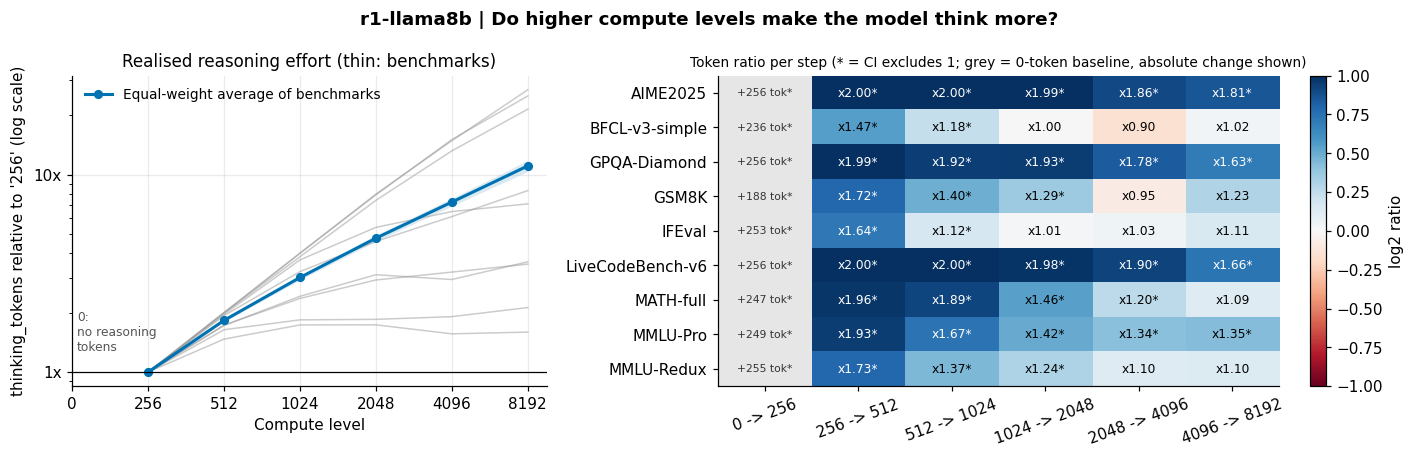

**Observed.** The average benchmark uses 11.1x the `thinking_tokens` at `8192` compared with `256` (the lowest level that produces reasoning tokens; `0` have no reasoning tokens, so no ratio is defined for them) (95% CI 10.4-11.8x). 7 of 9 benchmark(s) use more tokens at every successive level. Every step between adjacent levels clearly increases token use, so the levels differ in realised effort.

**Hypothesis.** Levels capped by a token limit (Section 9) flatten at the top of this curve.

In [108]:
real, real_tbl, real_steps = None, None, None
REF_I = 0                                   # index of the level used as the "1x" reference for effort ratios
if TOK is None:
    print("No token columns available; this section is skipped.")
else:
    ti = PRIMARY.values.index(TOK)
    tok_pt, tok_bt = PRIMARY.point[:, ti, :], PRIMARY.boot[:, :, ti, :]
    idx = np.flatnonzero(~np.isnan(tok_pt).any(axis=1))             # benchmarks observed at every level

    # A ratio to the lowest level is undefined when that level uses ZERO reasoning tokens (budget 0 / thinking off).
    # The reference is therefore the lowest level at which EVERY benchmark uses > 0 tokens; levels below it are
    # reported as absolute token counts and tested with an absolute difference instead of a ratio.
    pos = (tok_pt[idx] > 0).all(axis=0)
    if not pos.any():
        print(f"No compute level has {TOK} > 0 for every benchmark; the realised-compute ratios are skipped.")
        REF_I = 0
    else:
        REF_I = int(np.argmax(pos))
    REF_LV = LV[REF_I]
    if REF_I > 0:
        print(f"Levels {LV[:REF_I]} have no {TOK}; ratios are relative to '{REF_LV}', the lowest level with reasoning tokens.")

if TOK is not None and pos.any():
    ratio_pt = np.full_like(tok_pt, np.nan)
    ratio_bt = np.full_like(tok_bt, np.nan)
    ratio_pt[:, REF_I:] = tok_pt[:, REF_I:] / tok_pt[:, [REF_I]]
    ratio_bt[:, :, REF_I:] = tok_bt[:, :, REF_I:] / tok_bt[:, :, [REF_I]]
    real = Curve(point=np.nanmean(ratio_pt[idx], axis=0), boot=np.nanmean(ratio_bt[:, idx, :], axis=1),
                 cells=[PRIMARY.cells[k] for k in idx])
    tok_abs = Curve(point=np.mean(tok_pt[idx], axis=0), boot=np.mean(tok_bt[:, idx, :], axis=1))   # absolute tokens (equal weight)

    rows = []
    for k in idx:
        lo, hi = _ci(ratio_bt[:, k, -1])
        r = {"benchmark": PRIMARY.cells[k][0]}
        r.update({lv: v for lv, v in zip(LV, tok_pt[k])})
        r.update({f"ratio {LV[-1]}/{REF_LV}": ratio_pt[k, -1], "ci_low": lo, "ci_high": hi,
                  "more_tokens_at_every_step": bool((np.diff(tok_pt[k]) > 0).all())})
        rows.append(r)
    real_tbl = pd.DataFrame(rows).set_index("benchmark")
    print(f"Mean {TOK} per sample by benchmark and level (same questions at every level):")
    display(real_tbl)

    srows = []
    for j in range(L - 1):
        d_abs, a_lo, a_hi = tok_abs.diff(j, j + 1)
        if j < REF_I:                                    # baseline has no reasoning tokens -> ratio undefined, test the absolute change
            ratio, lo, hi = np.nan, np.nan, np.nan
            verdict = "more tokens" if a_lo > 0 else ("fewer tokens" if a_hi < 0 else "no clear change")
        else:
            ratio = real.point[j + 1] / real.point[j]
            lo, hi = _ci(real.boot[:, j + 1] / real.boot[:, j])
            verdict = "more tokens" if lo > 1 else ("fewer tokens" if hi < 1 else "no clear change")
        srows.append({"step": f"{LV[j]} -> {LV[j + 1]}", "token_ratio": ratio, "ci_low": lo, "ci_high": hi,
                      "abs_change_tokens": d_abs, "verdict": verdict})
    real_steps = pd.DataFrame(srows).set_index("step")
    print("Overall token change between adjacent levels (ratio of the equal-weight average of per-benchmark ratios; "
          "absolute change in tokens where the lower level has none):")
    display(real_steps)
    save_table(real_tbl, "02_realised_compute")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
    ax = axes[0]
    for k in idx:
        ax.plot(X, ratio_pt[k], color="#999999", alpha=0.5, lw=1)
    draw(ax, real.point, real.lo, real.hi, color=PALETTE[0], label="Equal-weight average of benchmarks")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}x"))
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    ax.axhline(1, color="black", lw=0.8)
    for j in range(REF_I):                               # levels without a defined ratio
        ax.annotate(f"{LV[j]}:\nno reasoning\ntokens", xy=(X[j], 1), xytext=(3, 12), textcoords="offset points",
                    ha="left", va="bottom", fontsize=8, color="#555555")
    level_axis(ax)
    ax.set_ylabel(f"{TOK} relative to '{REF_LV}' (log scale)")
    ax.set_title("Realised reasoning effort (thin: benchmarks)")
    ax.legend()

    R = np.full((len(idx), L - 1), np.nan)
    Sg = np.zeros_like(R, dtype=bool)
    for r_, k in enumerate(idx):
        for j in range(L - 1):
            if tok_pt[k, j] > 0:
                R[r_, j] = tok_pt[k, j + 1] / tok_pt[k, j]
                lo, hi = _ci(tok_bt[:, k, j + 1] / tok_bt[:, k, j])
                Sg[r_, j] = lo > 1 or hi < 1
            else:                                        # zero baseline: significance from the absolute difference
                lo, hi = _ci(tok_bt[:, k, j + 1] - tok_bt[:, k, j])
                Sg[r_, j] = lo > 0 or hi < 0
    logR = np.log2(R)
    fin = np.isfinite(logR)
    vmax = max(np.abs(logR[fin]).max() if fin.any() else 0.0, 1e-6)
    cmap = plt.get_cmap("RdBu").copy()
    cmap.set_bad("#e6e6e6")                              # undefined ratio (zero-token baseline)
    ax = axes[1]
    im = ax.imshow(np.ma.masked_invalid(logR), cmap=cmap, vmin=-vmax, vmax=vmax, aspect="auto")
    for r_, k in enumerate(idx):
        for j in range(L - 1):
            star = "*" if Sg[r_, j] else ""
            if np.isfinite(logR[r_, j]):
                ax.text(j, r_, f"x{R[r_, j]:.2f}{star}", ha="center", va="center", fontsize=8,
                        color="white" if abs(logR[r_, j]) > 0.6 * vmax else "black")
            else:
                ax.text(j, r_, f"+{tok_pt[k, j + 1] - tok_pt[k, j]:,.0f} tok{star}", ha="center", va="center", fontsize=7, color="#333333")
    ax.set_xticks(range(L - 1))
    ax.set_xticklabels([f"{LV[j]} -> {LV[j + 1]}" for j in range(L - 1)], rotation=20)
    ax.set_yticks(range(len(idx)))
    ax.set_yticklabels([PRIMARY.cells[k][0] for k in idx])
    ax.grid(False)
    ax.set_title("Token ratio per step (* = CI excludes 1; grey = 0-token baseline, absolute change shown)" if REF_I > 0
                 else "Token ratio per step (* = CI excludes 1)", fontsize=9 if REF_I > 0 else None)
    fig.colorbar(im, ax=ax, fraction=0.04, label="log2 ratio")
    finish(fig, "02_realised_compute", "Do higher compute levels make the model think more?",
           f"{LV[-1]} uses {real.point[-1]:.1f}x the tokens of {REF_LV}")

    n_mono = int(real_tbl["more_tokens_at_every_step"].sum())
    flat = real_steps.index[real_steps["verdict"] != "more tokens"].tolist()
    base_txt = (f"`{REF_LV}` (the lowest level that produces reasoning tokens; {', '.join('`' + x + '`' for x in LV[:REF_I])} "
                f"have no reasoning tokens, so no ratio is defined for them)") if REF_I > 0 else f"`{LV[0]}`"
    md(f"**Observed.** The average benchmark uses {real.point[-1]:.1f}x the `{TOK}` at `{LV[-1]}` compared with {base_txt} "
       f"({int(CI_LEVEL * 100)}% CI {real.lo[-1]:.1f}-{real.hi[-1]:.1f}x). {n_mono} of {len(real_tbl)} benchmark(s) use more tokens at every successive level. "
       + (f"Steps **without** a clear overall token increase: {flat}; accuracy differences across those steps cannot be attributed to extra reasoning effort."
          if flat else "Every step between adjacent levels clearly increases token use, so the levels differ in realised effort.")
       + "\n\n**Hypothesis.** Levels capped by a token limit (Section 9) flatten at the top of this curve.")

## 3. Headline: overall accuracy vs. compute

The primary curve is the **equal-weight (macro) average of benchmarks, same benchmarks and same questions at every level**. Three views of it are shown:

* **(a) By level, with the truncated share** (right axis). Truncation can explain a plateau or a drop at the top level, so it is drawn on the same plot.
* **(b) By realised effort.** Levels are not necessarily equally spaced in real compute, so accuracy is also plotted against the realised token ratio (Section 2) on a log axis.
* **(c) Gain over the lowest level**, in percentage points and as a **normalised gain** (share of the remaining headroom recovered), because 5 pp mean different things near the ceiling and near the floor.

The equal-weight-per-task-type curve is a check that a task type with many benchmarks does not dominate.

In [109]:
vi = PRIMARY.values.index("correct")
m_primary = macro(PRIMARY, "correct")
if m_primary is None:
    raise RuntimeError("No benchmark is observed at every compute level; a level-comparable curve cannot be built. See Section 1.2.")
sel = [PRIMARY.cells.index(c) for c in m_primary.cells]
print(f"Primary curve uses {len(sel)} benchmark(s): {[c[0] for c in m_primary.cells]}")
dropped = sorted({c[0] for c in est_all.cells} - {c[0] for c in m_primary.cells})
if dropped:
    print("Not in the primary curve (missing at >= 1 level, or no common questions):", dropped)


def ng_macro(est, v, where=None):
    """Equal-weight average of the per-benchmark normalised gains (headroom-aware)."""
    cv = macro(est, v, where)
    if cv is None:
        return None
    s, k = [est.cells.index(c) for c in cv.cells], est.values.index(v)
    return Curve(point=norm_gain(est.point[s, k, :]).mean(0), boot=norm_gain(est.boot[:, s, k, :]).mean(1), cells=cv.cells)


# Task-type curves come from the SAME object and the SAME resampled questions, so differences to m_primary are valid.
type_curves = {t: macro(PRIMARY, "correct", where=lambda c, t=t: TYPE_OF[c[0]] == t) for t in sorted(set(TYPE_OF.values()))}
type_curves = {t: cv for t, cv in type_curves.items() if cv is not None}
m_types = (Curve(point=np.mean([c.point for c in type_curves.values()], axis=0), boot=np.mean([c.boot for c in type_curves.values()], axis=0))
           if type_curves else None)
m_ng = ng_macro(PRIMARY, "correct")
m_trunc = macro(PRIMARY, "was_truncated") if "was_truncated" in VALUES else None

agg = pd.DataFrame({"accuracy": m_primary.point, "ci_low": m_primary.lo, "ci_high": m_primary.hi,
                    "change_pp": 100 * m_primary.rel().point, "normalised_gain": m_ng.point, "ng_ci_low": m_ng.lo, "ng_ci_high": m_ng.hi,
                    "accuracy_equal_task_types": m_types.point if m_types else np.nan,
                    "truncated_share": m_trunc.point if m_trunc else np.nan,
                    "token_ratio_vs_ref_level": real.point if real is not None else np.nan}, index=LV)
display(agg)
if real is not None and REF_I > 0:
    print(f"token_ratio_vs_ref_level is relative to '{LV[REF_I]}' (levels {LV[:REF_I]} have no reasoning tokens, so their ratio is undefined).")
save_table(agg, "03_headline")

Primary curve uses 9 benchmark(s): ['AIME2025', 'BFCL-v3-simple', 'GPQA-Diamond', 'GSM8K', 'IFEval', 'LiveCodeBench-v6', 'MATH-full', 'MMLU-Pro', 'MMLU-Redux']


,accuracy,ci_low,ci_high,change_pp,normalised_gain,ng_ci_low,ng_ci_high,accuracy_equal_task_types,truncated_share,token_ratio_vs_ref_level
0,0.404,0.360,0.447,0.000,0.000,0.000,0.000,0.412,0.070,NaN
256,0.427,0.386,0.467,2.296,0.025,-0.065,0.090,0.436,0.121,1.000
512,0.445,0.406,0.487,4.148,0.066,-0.029,0.137,0.462,0.130,1.827
1024,0.442,0.401,0.484,3.852,0.068,-0.020,0.134,0.457,0.150,3.012
2048,0.467,0.424,0.510,6.296,0.107,0.026,0.175,0.477,0.136,4.763
4096,0.489,0.444,0.533,8.519,0.146,0.069,0.215,0.499,0.083,7.254
8192,0.499,0.456,0.543,9.481,0.168,0.087,0.238,0.513,0.063,11.058


token_ratio_vs_ref_level is relative to '256' (levels ['0'] have no reasoning tokens, so their ratio is undefined).
Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__03_headline.csv


Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__03_headline.png


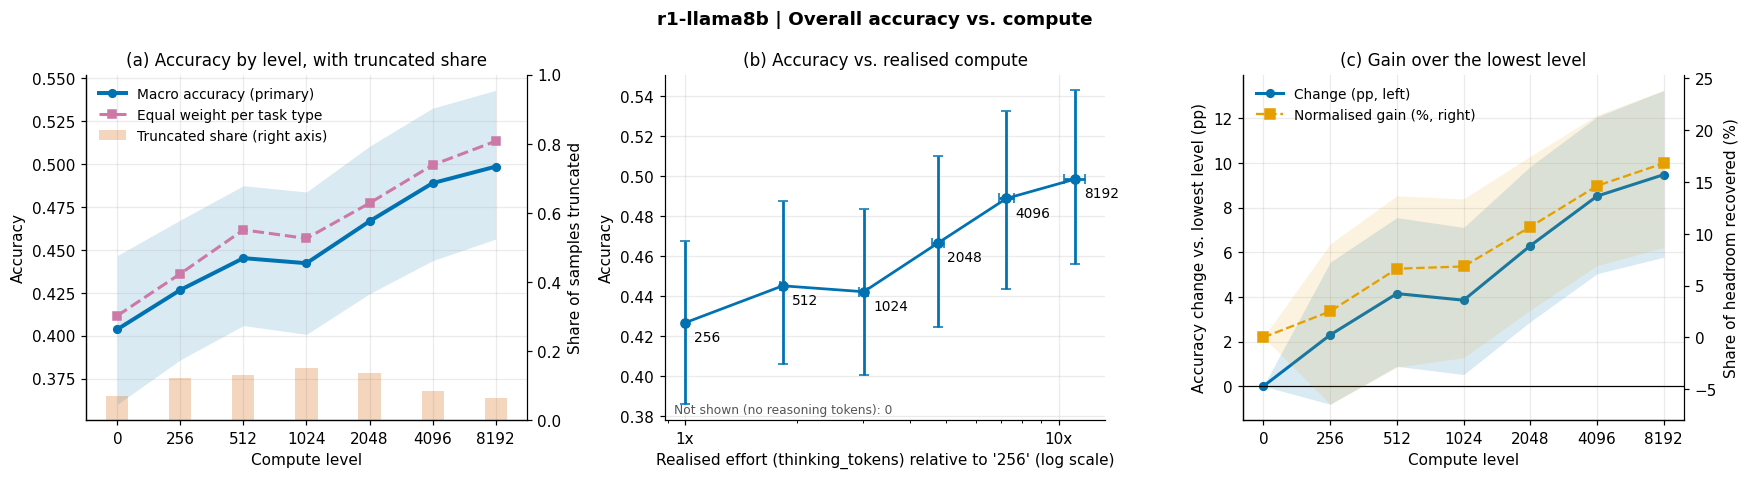

**Observed.** Primary macro accuracy goes from 40.4% at `0` to 49.9% at `8192`: +9.5 pp [95% CI +5.8 pp, +13.3 pp], *increase*; normalised gain 17% [9%, 24%]. Highest point estimate at `8192`. With equal weight per task type the change is +10.2 pp [+6.0 pp, +14.6 pp]. The truncated share moves from 7.0% to 6.3%; read any plateau or drop at the top together with it (Section 9).

In [110]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

ax = axes[0]                                                  # (a) by level + truncated share
draw(ax, m_primary.point, m_primary.lo, m_primary.hi, color=PALETTE[0], label="Macro accuracy (primary)", lw=2.6)
if m_types:
    draw(ax, m_types.point, m_types.lo, m_types.hi, color=PALETTE[4], ls="--", marker="s", band=False, label="Equal weight per task type")
level_axis(ax)
ax.set_ylabel("Accuracy")
ax.set_title("(a) Accuracy by level, with truncated share")
if m_trunc is not None:
    ax2 = ax.twinx()
    ax2.bar(X, m_trunc.point, width=0.35, color=PALETTE[3], alpha=0.25, label="Truncated share (right axis)")
    ax2.set_ylim(0, 1)
    ax2.set_ylabel("Share of samples truncated")
    ax2.grid(False)
    ax2.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels() if m_trunc is not None else ([], [])
ax.legend(h1 + h2, l1 + l2, loc="best")

ax = axes[1]                                                  # (b) by realised effort (log x)
if real is not None:
    ok = np.isfinite(real.point)                              # levels without a defined ratio (0 reasoning tokens) are not drawn
    yerr_ = np.clip(np.array([m_primary.point - m_primary.lo, m_primary.hi - m_primary.point])[:, ok], 0, None)
    xerr_ = np.clip(np.array([real.point - real.lo, real.hi - real.point])[:, ok], 0, None)
    ax.errorbar(real.point[ok], m_primary.point[ok], yerr=yerr_, xerr=xerr_, fmt="o-", color=PALETTE[0], capsize=3, lw=1.8)
    for x, y, lv in zip(real.point[ok], m_primary.point[ok], np.array(LV)[ok]):
        ax.annotate(lv, (x, y), textcoords="offset points", xytext=(6, -12), fontsize=9)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}x"))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    if REF_I > 0:
        ax.text(0.02, 0.02, f"Not shown (no reasoning tokens): {', '.join(LV[:REF_I])}", transform=ax.transAxes, fontsize=8, color="#555555")
ax.set_xlabel(f"Realised effort ({TOK}) relative to '{LV[REF_I]}' (log scale)")
ax.set_ylabel("Accuracy")
ax.set_title("(b) Accuracy vs. realised compute")

ax = axes[2]                                                  # (c) gain in pp and as normalised gain
rel = m_primary.rel()
draw(ax, 100 * rel.point, 100 * rel.lo, 100 * rel.hi, color=PALETTE[0], label="Change (pp, left)")
ax.axhline(0, color="black", lw=0.8)
level_axis(ax)
ax.set_ylabel("Accuracy change vs. lowest level (pp)")
ax.set_title("(c) Gain over the lowest level")
ax3 = ax.twinx()
ax3.plot(X, 100 * m_ng.point, ls="--", marker="s", color=PALETTE[1], label="Normalised gain (%, right)")
ax3.fill_between(X, 100 * m_ng.lo, 100 * m_ng.hi, color=PALETTE[1], alpha=0.12, lw=0)
ax3.set_ylabel("Share of headroom recovered (%)")
ax3.grid(False)
ax3.spines["right"].set_visible(True)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax3.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")

dm, dm_lo, dm_hi = m_primary.diff(0, -1)
ng_last = m_ng.point[-1]
finish(fig, "03_headline", "Overall accuracy vs. compute", f"Accuracy {pp(dm)} from {LV[0]} to {LV[-1]} ({ng_last:.0%} of the headroom)")

best_i = int(np.argmax(m_primary.point))
txt = (f"**Observed.** Primary macro accuracy goes from {pct(m_primary.point[0])} at `{LV[0]}` to {pct(m_primary.point[-1])} at `{LV[-1]}`: "
       f"{pp(dm)} [{int(CI_LEVEL * 100)}% CI {pp(dm_lo)}, {pp(dm_hi)}], *{sig(dm_lo, dm_hi)}*; normalised gain {ng_last:.0%} "
       f"[{m_ng.lo[-1]:.0%}, {m_ng.hi[-1]:.0%}]. Highest point estimate at `{LV[best_i]}`.")
if m_types:
    dt_, dt_lo, dt_hi = m_types.diff(0, -1)
    txt += f" With equal weight per task type the change is {pp(dt_)} [{pp(dt_lo)}, {pp(dt_hi)}]."
if m_trunc is not None:
    txt += f" The truncated share moves from {pct(m_trunc.point[0])} to {pct(m_trunc.point[-1])}; read any plateau or drop at the top together with it (Section 9)."
md(txt)

## 4. Per-benchmark behaviour: does every benchmark follow the headline?

For each benchmark the change from the lowest to the highest level is estimated on identical questions, with:

* a paired bootstrap interval and p-value, **Holm-adjusted across benchmarks** (the verdict uses the adjusted p-value);
* the **normalised gain**, so ceiling and floor benchmarks are comparable;
* a **trend test** over all levels (logistic slope per level step, standard errors clustered on the question), which uses every level instead of the two extremes.

In [111]:
def logit_fit(formula, data):
    """Logistic regression of `correct` with standard errors clustered on the question. None if it cannot be fitted."""
    if not HAS_SM or data.empty:
        return None
    g = pd.factorize(data["benchmark"] + "|" + data["question_id"])[0]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            return smf.logit(formula, data).fit(disp=0, cov_type="cluster", cov_kwds={"groups": g}, maxiter=200)
    except Exception as e:
        print("  (model could not be fitted:", repr(e), ")")
        return None


def drop_constant(data, by):
    """Remove groups whose outcome never varies (they carry no information and cause separation)."""
    m = data.groupby(by)["correct"].transform("mean")
    return data[(m > 0) & (m < 1)]


def wald_p(res, prefix):
    """Joint Wald p-value that all coefficients whose name starts with `prefix` are zero."""
    if res is None:
        return np.nan
    pos = [i for i, n in enumerate(res.params.index) if n.startswith(prefix)]
    if not pos:
        return np.nan
    R = np.zeros((len(pos), len(res.params)))
    for r, i in enumerate(pos):
        R[r, i] = 1
    return float(res.wald_test(R, use_f=False, scalar=True).pvalue)


rows = []
for i, cell in enumerate(PRIMARY.cells):
    b = cell[0]
    p, lo, hi = cell_curve(PRIMARY, cell, "correct")
    bd = PRIMARY.boot[:, i, vi, -1] - PRIMARY.boot[:, i, vi, 0]
    lo_d, hi_d = _ci(bd)
    ng_b = norm_gain(PRIMARY.boot[:, i, vi, :])[:, -1]
    ng_lo, ng_hi = _ci(ng_b)
    sub = d_bal[d_bal.benchmark == b]
    res = logit_fit("correct ~ lvl", sub) if 0 < sub["correct"].mean() < 1 else None
    r = {"benchmark": b, "task_type": TYPE_OF[b], "questions": PRIMARY.nq[i]}
    r.update({lv: v for lv, v in zip(LV, p)})
    r.update({"peak_level": LV[int(np.nanargmax(p))], "delta": PRIMARY.point[i, vi, -1] - PRIMARY.point[i, vi, 0], "ci_low": lo_d, "ci_high": hi_d,
              "p_delta": boot_p(bd), "norm_gain": norm_gain(PRIMARY.point[i, vi])[-1], "ng_ci_low": ng_lo, "ng_ci_high": ng_hi,
              "trend_OR_per_step": float(np.exp(res.params["lvl"])) if res is not None else np.nan,
              "p_trend": float(res.pvalues["lvl"]) if res is not None else np.nan,
              "low_n": bool((q_cov.loc[b] < MIN_QUESTIONS_PER_CELL).any())})
    rows.append(r)
bench_tbl = pd.DataFrame(rows).set_index("benchmark")
bench_tbl["p_delta_holm"] = holm(bench_tbl["p_delta"].values)
bench_tbl["p_trend_holm"] = holm(bench_tbl["p_trend"].values)
bench_tbl["verdict"] = [verdict_p(dl, ph) for dl, ph in zip(bench_tbl["delta"], bench_tbl["p_delta_holm"])]
print(f"Accuracy per benchmark and level; change '{LV[0]}' -> '{LV[-1]}' on identical questions (delta as a fraction; {int(CI_LEVEL * 100)}% paired bootstrap CI), "
      "normalised gain, and Holm-adjusted p-values:")
display(bench_tbl)
save_table(bench_tbl, "04_per_benchmark")

# pooled trend over the ordinal level (benchmark fixed effects): a test of the headline that uses every level
pool = drop_constant(d_bal, "benchmark")
res_pool = logit_fit("correct ~ C(benchmark) + lvl", pool) if pool["benchmark"].nunique() else None
if res_pool is not None:
    md(f"**Trend over all levels.** Each step up in compute level multiplies the odds of a correct answer by "
       f"{np.exp(res_pool.params['lvl']):.2f} (p = {res_pool.pvalues['lvl']:.3g}; logistic model with benchmark fixed effects, question-clustered errors). "
       "This is a test of the direction of the effect, not the headline estimate, which stays the equal-weight macro curve.")

Accuracy per benchmark and level; change '0' -> '8192' on identical questions (delta as a fraction; 95% paired bootstrap CI), normalised gain, and Holm-adjusted p-values:


,task_type,questions,0,256,512,1024,2048,4096,8192,peak_level,delta,ci_low,ci_high,p_delta,norm_gain,ng_ci_low,ng_ci_high,trend_OR_per_step,p_trend,low_n,p_delta_holm,p_trend_holm,verdict
benchmark,,,,,,,,,,,,,,,,,,,,,,,
AIME2025,Open-ended,30,0.073,0.107,0.100,0.100,0.173,0.233,0.227,4096,0.153,0.080,0.227,0.001,0.165,0.086,0.250,1.266,0.001,False,0.009,0.010,increase
BFCL-v3-simple,Open-ended,30,0.353,0.367,0.313,0.327,0.313,0.313,0.320,256,-0.033,-0.093,0.020,0.269,-0.052,-0.173,0.027,0.967,0.164,False,0.980,0.612,no clear change
GPQA-Diamond,MCQ,30,0.313,0.313,0.413,0.373,0.347,0.393,0.407,512,0.093,-0.060,0.253,0.245,0.136,-0.097,0.333,1.059,0.278,False,0.980,0.612,no clear change
GSM8K,Open-ended,30,0.680,0.627,0.760,0.760,0.740,0.713,0.747,1024,0.067,-0.053,0.180,0.276,0.208,-0.222,0.500,1.064,0.122,False,0.980,0.612,no clear change
IFEval,Open-ended,30,0.447,0.573,0.607,0.560,0.593,0.587,0.547,512,0.100,-0.013,0.227,0.076,0.181,-0.025,0.385,1.046,0.123,False,0.380,0.612,no clear change
LiveCodeBench-v6,Open-ended,30,0.107,0.107,0.093,0.133,0.167,0.207,0.207,4096,0.100,0.020,0.193,0.011,0.112,0.023,0.221,1.183,0.009,False,0.077,0.064,no clear change
MATH-full,Open-ended,30,0.667,0.667,0.600,0.600,0.687,0.753,0.767,8192,0.100,-0.000,0.200,0.062,0.300,-0.000,0.604,1.096,0.058,False,0.372,0.351,no clear change
MMLU-Pro,MCQ,30,0.347,0.453,0.500,0.440,0.533,0.520,0.587,8192,0.240,0.107,0.367,0.001,0.367,0.180,0.537,1.137,0.003,False,0.009,0.023,increase
MMLU-Redux,MCQ,30,0.647,0.627,0.620,0.687,0.647,0.680,0.680,1024,0.033,-0.080,0.140,0.561,0.094,-0.281,0.375,1.038,0.243,False,0.980,0.612,no clear change


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__04_per_benchmark.csv


**Trend over all levels.** Each step up in compute level multiplies the odds of a correct answer by 1.08 (p = 2.33e-07; logistic model with benchmark fixed effects, question-clustered errors). This is a test of the direction of the effect, not the headline estimate, which stays the equal-weight macro curve.

Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__04_per_benchmark.png


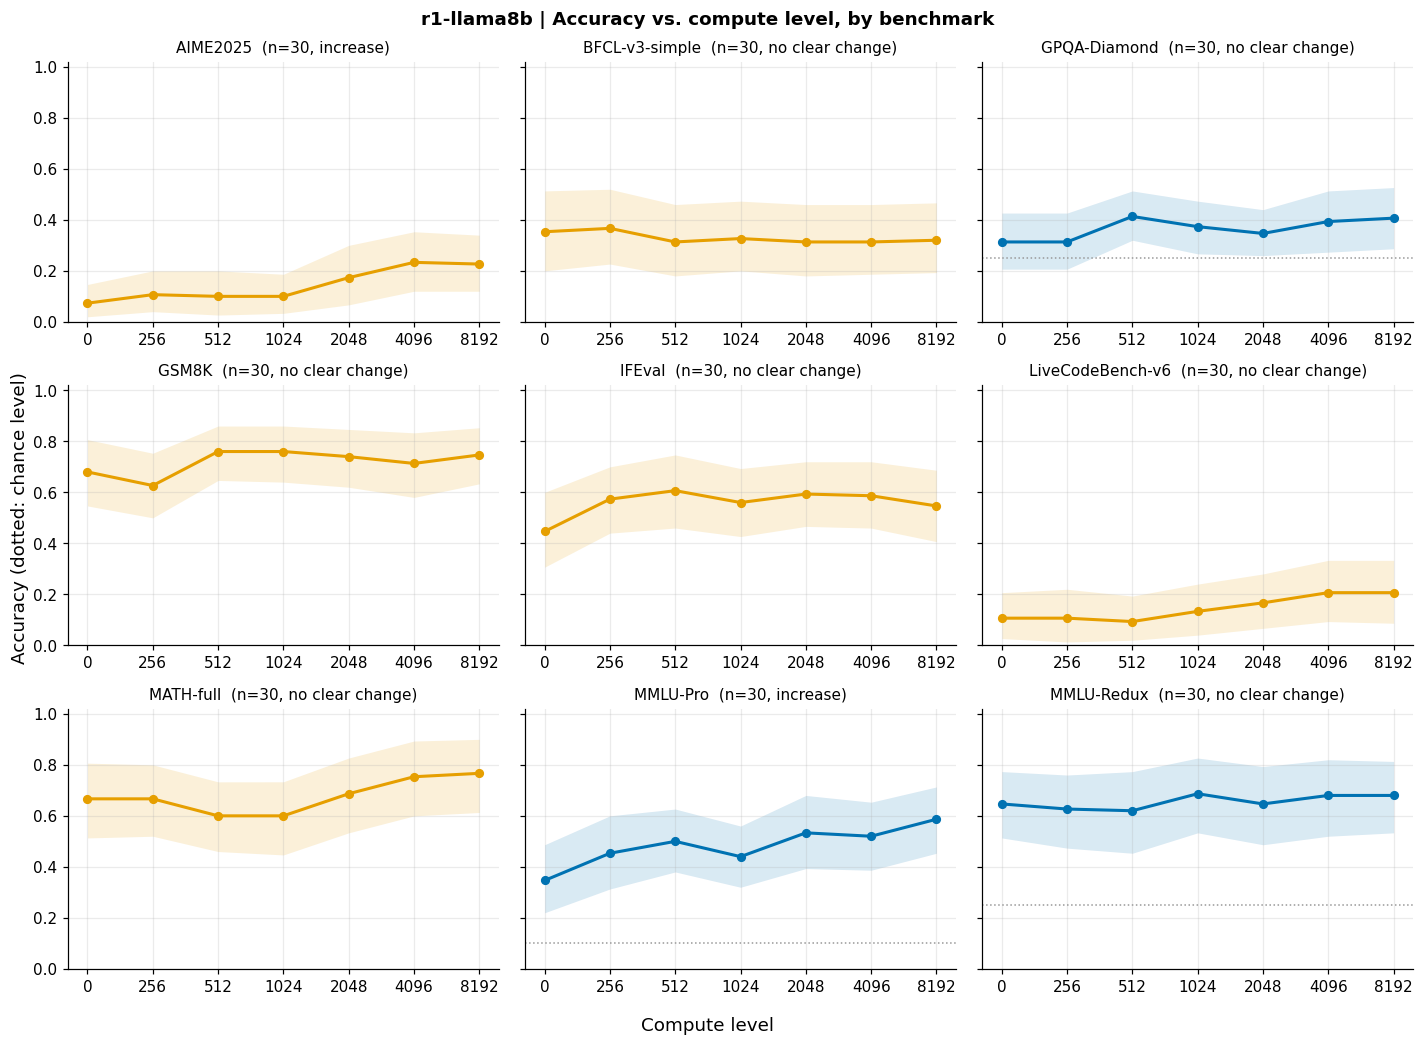

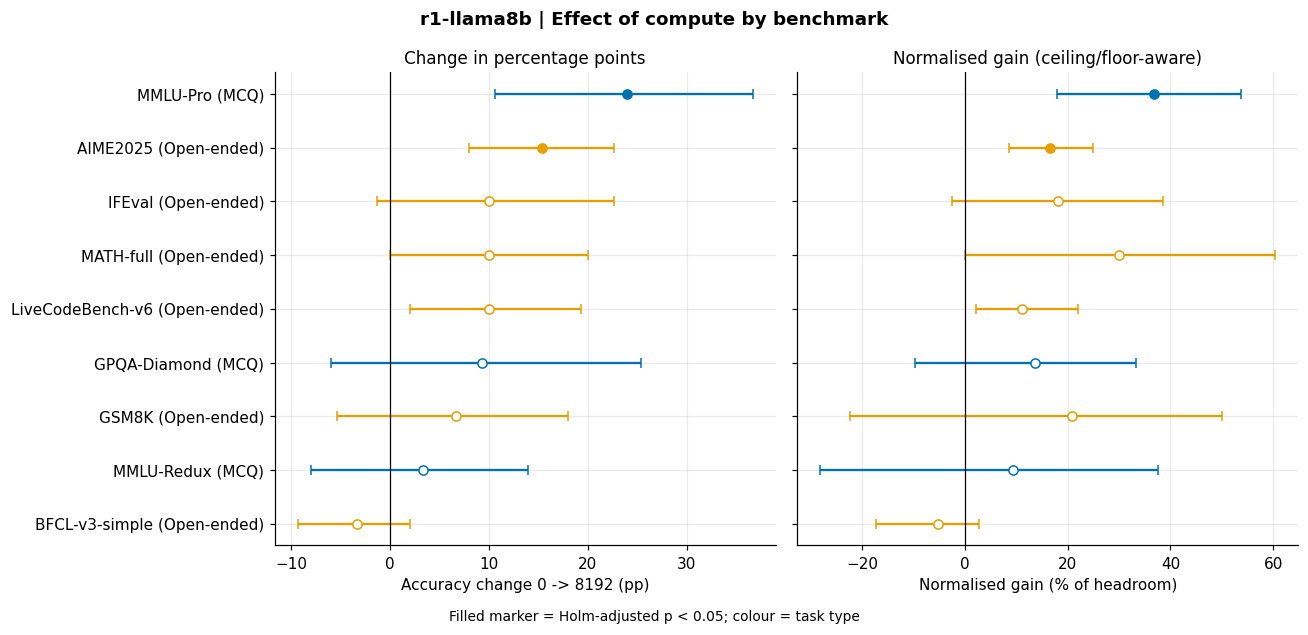

**Observed.** On identical questions between `0` and `8192` (Holm-adjusted): 2 benchmark(s) increase, 0 decrease, 7 show no clear change.

**Reading the flat ones.** Compare the level columns with the normalised gain: a benchmark at the ceiling or at chance level has little headroom, so a small pp change is not evidence that compute is useless there. Benchmarks that decline may suffer from truncation at high compute (Section 9).

In [112]:
# ------------------------- small multiples: accuracy per benchmark ------------------------
n_bm = len(PRIMARY.cells)
ncols = min(3, n_bm)
nrows = math.ceil(n_bm / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.2 * nrows), sharey=True, squeeze=False)
for ax in axes.ravel()[n_bm:]:
    ax.axis("off")
for ax, cell in zip(axes.ravel(), PRIMARY.cells):
    b = cell[0]
    p, lo, hi = cell_curve(PRIMARY, cell, "correct")
    draw(ax, p, lo, hi, color=TYPE_COLOR[TYPE_OF[b]])
    if b in CHANCE:
        ax.axhline(CHANCE[b], color="#999999", ls=":", lw=1)
    ax.set_title(f"{b}  (n={PRIMARY.nq[PRIMARY.cells.index(cell)]}, {bench_tbl.loc[b, 'verdict']})", fontsize=10)
    level_axis(ax, label=False)
    ax.set_ylim(0, 1.02)
fig.supxlabel("Compute level")
fig.supylabel("Accuracy (dotted: chance level)")
v = bench_tbl["verdict"].value_counts()
take = f"{v.get('increase', 0)} benchmarks improve, {v.get('no clear change', 0)} are flat, {v.get('decrease', 0)} decline"
finish(fig, "04_per_benchmark", "Accuracy vs. compute level, by benchmark", take)

# ------------------------- forest: deltas in pp and normalised gain -----------------------
order = bench_tbl.sort_values("delta").index
fig, axes = plt.subplots(1, 2, figsize=(12, max(3, 0.45 * len(order) + 1.5)), sharey=True)
for ax, (col, lo_c, hi_c, scale, xl) in zip(axes, [("delta", "ci_low", "ci_high", 100, f"Accuracy change {LV[0]} -> {LV[-1]} (pp)"),
                                                  ("norm_gain", "ng_ci_low", "ng_ci_high", 100, "Normalised gain (% of headroom)")]):
    for y, b in enumerate(order):
        r = bench_tbl.loc[b]
        filled = r["p_delta_holm"] < ALPHA
        ax.errorbar(scale * r[col], y, xerr=[[scale * (r[col] - r[lo_c])], [scale * (r[hi_c] - r[col])]], fmt="o", color=TYPE_COLOR[r["task_type"]],
                    mfc=TYPE_COLOR[r["task_type"]] if filled else "white", capsize=3)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel(xl)
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels([f"{b} ({bench_tbl.loc[b, 'task_type']})" for b in order])
axes[0].set_title("Change in percentage points")
axes[1].set_title("Normalised gain (ceiling/floor-aware)")
fig.text(0.5, -0.02, "Filled marker = Holm-adjusted p < %.2f; colour = task type" % ALPHA, ha="center", fontsize=9)
finish(fig, "04_forest", "Effect of compute by benchmark", take)

n_low = int(bench_tbl["low_n"].sum())
md(f"**Observed.** On identical questions between `{LV[0]}` and `{LV[-1]}` (Holm-adjusted): {v.get('increase', 0)} benchmark(s) increase, "
   f"{v.get('decrease', 0)} decrease, {v.get('no clear change', 0)} show no clear change"
   + (f"; {n_low} benchmark(s) carry a `low_n` flag and need extra caution." if n_low else ".")
   + "\n\n**Reading the flat ones.** Compare the level columns with the normalised gain: a benchmark at the ceiling or at chance level has little headroom, "
     "so a small pp change is not evidence that compute is useless there. Benchmarks that decline may suffer from truncation at high compute (Section 9).")

## 5. Robustness: is one benchmark driving the headline?

Leave-one-benchmark-out: recompute the primary change after dropping each benchmark in turn.

Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__05_leave_one_out.png


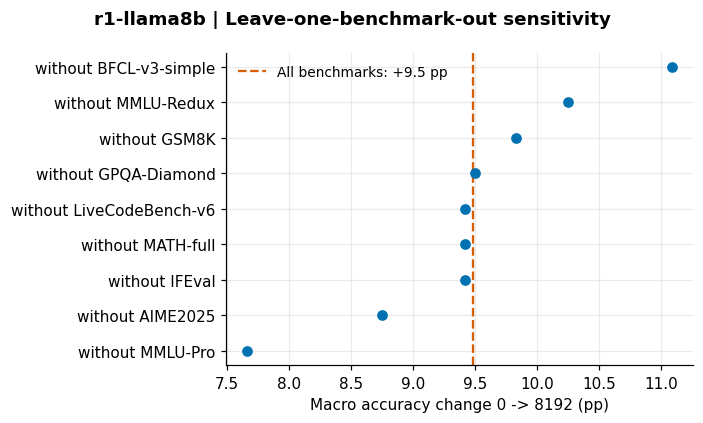

Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__05_leave_one_out.csv


**Observed.** Dropping any single benchmark moves the primary change within [+7.7 pp, +11.1 pp] (full set: +9.5 pp). A wide range means the aggregate rests on a few benchmarks.

In [113]:
full_delta = m_primary.point[-1] - m_primary.point[0]
loo = pd.Series(dtype=float)
if len(sel) > 1:
    loo = pd.Series({PRIMARY.cells[i][0]: (lambda p: p[-1] - p[0])(PRIMARY.point[[k for k in sel if k != i], vi, :].mean(axis=0)) for i in sel}).sort_values()
    fig, ax = plt.subplots(figsize=(6.5, max(2.5, 0.32 * len(loo) + 1)))
    ax.scatter(100 * loo.values, range(len(loo)), color=PALETTE[0], zorder=3)
    ax.axvline(100 * full_delta, color=PALETTE[3], ls="--", label=f"All benchmarks: {pp(full_delta)}")
    ax.set_yticks(range(len(loo)))
    ax.set_yticklabels([f"without {b}" for b in loo.index])
    ax.set_xlabel(f"Macro accuracy change {LV[0]} -> {LV[-1]} (pp)")
    ax.legend()
    finish(fig, "05_leave_one_out", "Leave-one-benchmark-out sensitivity", f"No single benchmark drives the result ({pp(loo.min())} to {pp(loo.max())})")
    save_table(loo.rename("macro_change_without"), "05_leave_one_out")
    md(f"**Observed.** Dropping any single benchmark moves the primary change within [{pp(loo.min())}, {pp(loo.max())}] (full set: {pp(full_delta)}). "
       "A wide range means the aggregate rests on a few benchmarks.")
else:
    print("Only one benchmark in the primary curve; leave-one-out is not informative.")

## 6. Why benchmarks differ (1): task type

Task types differ in chance level and headroom, so their *accuracy levels* are not comparable but their *scaling shape* can be. Each type is the equal-weight average of its benchmarks (same questions at every level). The right panel uses the normalised gain so that a type close to the ceiling is not penalised.

Whether the types really scale differently is tested formally: a **compute x task-type interaction** in a logistic model with benchmark fixed effects and question-clustered errors. Non-overlapping intervals are not a test; overlapping intervals do not prove equal scaling. A type backed by a single benchmark cannot be separated from that benchmark.

,benchmarks,macro@0,macro@256,macro@512,macro@1024,macro@2048,macro@4096,macro@8192,delta,ci_low,ci_high,p_delta,norm_gain,ng_ci_low,ng_ci_high,p_delta_holm,verdict
task_type,,,,,,,,,,,,,,,,,
MCQ,3,0.436,0.464,0.511,0.500,0.509,0.531,0.558,0.122,0.049,0.204,0.003,0.199,0.050,0.330,0.003,increase
Open-ended,6,0.388,0.408,0.412,0.413,0.446,0.468,0.469,0.081,0.041,0.121,0.001,0.152,0.054,0.237,0.002,increase


Compute x task-type interaction (joint Wald test): p = 0.985
Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__06_task_types.csv
Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__06_task_types.png


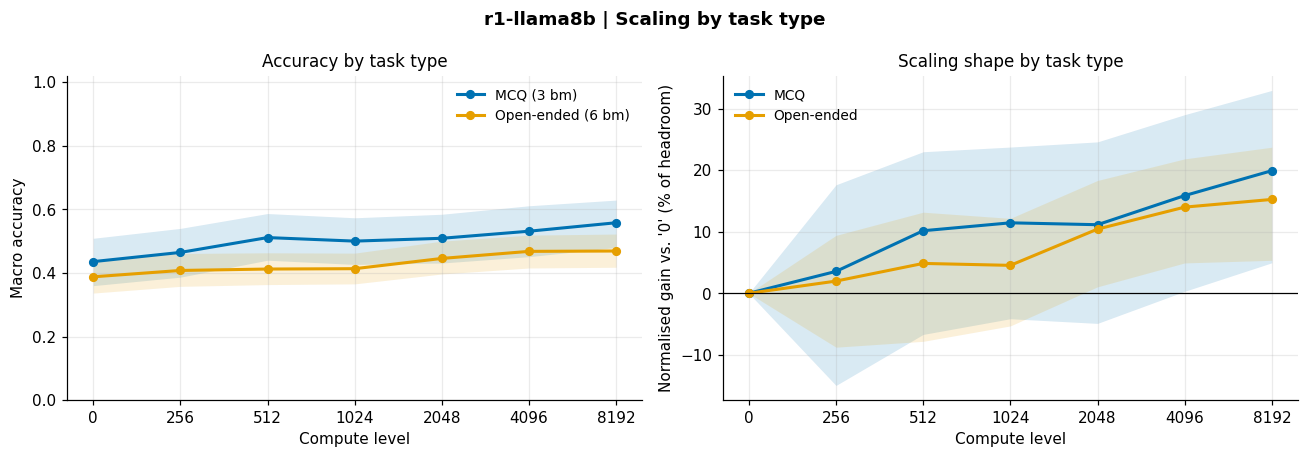

**Observed.** Change `0` -> `8192` (macro, 95% CI): MCQ: +12.2 pp [+4.9 pp, +20.4 pp], normalised 20%; Open-ended: +8.1 pp [+4.1 pp, +12.1 pp], normalised 15%. Interaction test: p = 0.985 (no evidence that the types scale differently).

**Hypothesis.** MCQ has a chance floor and limited headroom, which compresses its gains; open-ended tasks may gain more because multi-step reasoning matters more.

In [114]:
tt_ng = {t: ng_macro(PRIMARY, "correct", where=lambda c, t=t: TYPE_OF[c[0]] == t) for t in type_curves}
rows = []
for t, cv in type_curves.items():
    dl, lo, hi = cv.diff(0, -1)
    nlo, nhi = _ci(tt_ng[t].boot[:, -1])
    row = {"task_type": t, "benchmarks": len(cv.cells)}
    row.update({f"macro@{lv}": v for lv, v in zip(LV, cv.point)})
    row.update({"delta": dl, "ci_low": lo, "ci_high": hi, "p_delta": cv.p(0, -1), "norm_gain": tt_ng[t].point[-1], "ng_ci_low": nlo, "ng_ci_high": nhi})
    rows.append(row)
tt_tbl = pd.DataFrame(rows).set_index("task_type")
if len(tt_tbl):
    tt_tbl["p_delta_holm"] = holm(tt_tbl["p_delta"].values)
    tt_tbl["verdict"] = [verdict_p(a, b) for a, b in zip(tt_tbl["delta"], tt_tbl["p_delta_holm"])]
display(tt_tbl)

p_int_tt = np.nan
if len(type_curves) > 1:
    res_tt = logit_fit("correct ~ C(benchmark) + lvl + lvl:C(task_type_final)", drop_constant(d_bal, "benchmark"))
    p_int_tt = wald_p(res_tt, "lvl:")
    print(f"Compute x task-type interaction (joint Wald test): p = {p_int_tt:.3g}")
single = [t for t, cv in type_curves.items() if len(cv.cells) == 1]
if single:
    print("NOTE: task types backed by a single benchmark (type effect indistinguishable from benchmark effect):", single)
save_table(tt_tbl, "06_task_types")

T = len(type_curves)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for k, (t, cv) in enumerate(type_curves.items()):
    draw(axes[0], cv.point, cv.lo, cv.hi, color=TYPE_COLOR[t], label=f"{t} ({len(cv.cells)} bm)")
    g = tt_ng[t]
    draw(axes[1], 100 * g.point, 100 * g.lo, 100 * g.hi, color=TYPE_COLOR[t], label=t)
axes[0].set_ylim(0, 1.02)
axes[0].set_ylabel("Macro accuracy")
axes[0].set_title("Accuracy by task type")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel(f"Normalised gain vs. '{LV[0]}' (% of headroom)")
axes[1].set_title("Scaling shape by task type")
for ax in axes:
    level_axis(ax)
    ax.legend()
obs = "; ".join(f"{t}: {pp(r.delta)} [{pp(r.ci_low)}, {pp(r.ci_high)}], normalised {r.norm_gain:.0%}" for t, r in tt_tbl.iterrows())
take = "; ".join(f"{t} {pp(r.delta)}" for t, r in tt_tbl.iterrows())
finish(fig, "06_task_types", "Scaling by task type", take + (f" (interaction p = {p_int_tt:.2g})" if not np.isnan(p_int_tt) else ""))
md(f"**Observed.** Change `{LV[0]}` -> `{LV[-1]}` (macro, {int(CI_LEVEL * 100)}% CI): {obs}."
   + (f" Interaction test: p = {p_int_tt:.3g} ({'the types scale differently' if p_int_tt < ALPHA else 'no evidence that the types scale differently'})." if not np.isnan(p_int_tt) else "")
   + "\n\n**Hypothesis.** MCQ has a chance floor and limited headroom, which compresses its gains; open-ended tasks may gain more because multi-step reasoning matters more.")

## 7. Why benchmarks differ (2): difficulty

Does extra compute help easy, medium or hard questions most, and does the model think more on hard questions? Each *benchmark x tier* is a cell (same questions at every level); tiers are equal-weight averages over the benchmarks that contain them. Tiers are defined **within** each benchmark, so "hard" is not comparable across benchmarks.

**How tiers are defined (`DIFFICULTY_SOURCE`).**

* `"metadata"` – the `difficulty_tier` column is used as given. If it comes from the benchmark itself this is fine. If it was derived from the model's own pass rate, low-accuracy tiers are partly selected for bad luck and will appear to gain more simply through regression to the mean.
* `"split_half"` – tiers are rebuilt from the pass rate on half of the samples (even `sample_index`, all levels pooled) and accuracy is measured on the other half (odd `sample_index`), which removes that bias.

The compute x tier interaction is tested formally, as in Section 6.

Difficulty: tiers from the `difficulty_tier` column


,benchmarks,questions,0,256,512,1024,2048,4096,8192,delta,ci_low,ci_high,p_delta,norm_gain,p_delta_holm,verdict
tier,,,,,,,,,,,,,,,,
easy,3,90,0.591,0.609,0.662,0.669,0.660,0.660,0.658,0.067,-0.000,0.138,0.054,0.161,0.054,no clear change
medium,3,90,0.456,0.496,0.471,0.456,0.511,0.529,0.558,0.102,0.044,0.158,0.002,0.205,0.006,increase
hard,3,90,0.164,0.176,0.202,0.202,0.229,0.278,0.280,0.116,0.051,0.178,0.003,0.138,0.006,increase


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__07_difficulty.csv
Compute x difficulty-tier interaction (joint Wald test): p = 0.112
Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__07_difficulty.png


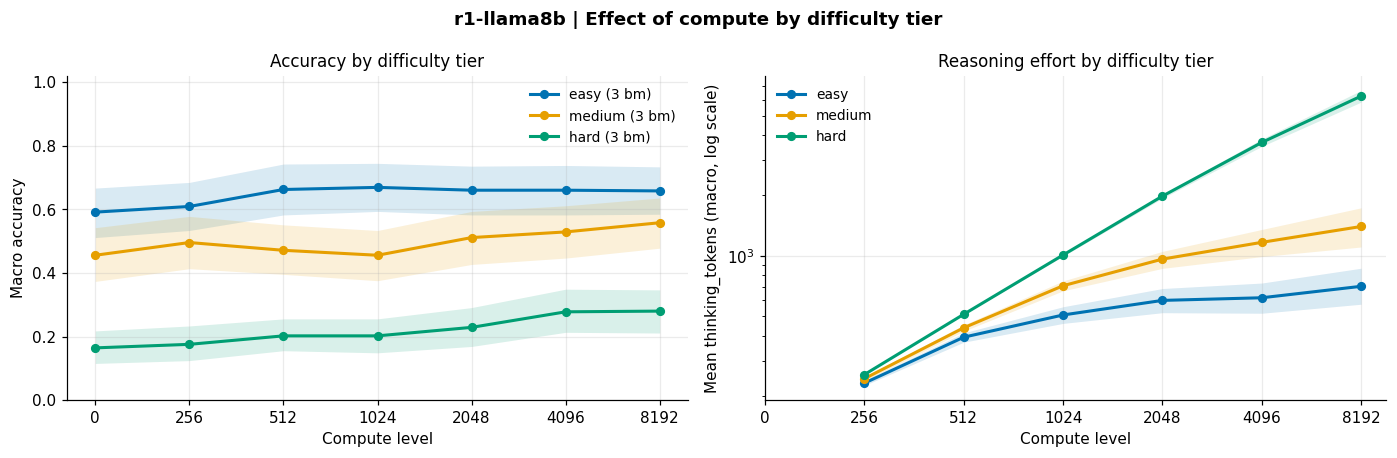

**Observed** (tiers from the `difficulty_tier` column). Change `0` -> `8192` by tier: easy: +6.7 pp [-0.0 pp, +13.8 pp], normalised 16%; medium: +10.2 pp [+4.4 pp, +15.8 pp], normalised 21%; hard: +11.6 pp [+5.1 pp, +17.8 pp], normalised 14%. Interaction test: p = 0.112.

**How to read.** If harder tiers gain more, compute buys capability where headroom exists; easy tiers flat near 100 % are a ceiling effect, not evidence that compute is useless for them. The right panel shows whether the model spends more tokens on harder questions (adaptive effort) or a similar budget regardless.

In [115]:
d_dt = d[d["difficulty_tier"] != "unknown"].copy()
tier_note = "tiers from the `difficulty_tier` column"
if DIFFICULTY_SOURCE == "split_half":
    half = d["sample_index"].astype(int) % 2
    pr = d[half == 0].groupby(["benchmark", "question_id"])["correct"].mean()
    pct_rank = pr.groupby(level=0).rank(method="first", pct=True)
    tiers = pd.cut(pct_rank, [0, 1 / 3, 2 / 3, 1.0], labels=["hard", "medium", "easy"]).astype(str).rename("difficulty_tier").reset_index()
    d_dt = d[half == 1].drop(columns="difficulty_tier").merge(tiers, on=["benchmark", "question_id"], how="inner")
    tier_note = "tiers rebuilt from half of the samples and measured on the other half"
    TIER_ORDER_USED = ["easy", "medium", "hard"]
else:
    TIER_ORDER_USED = TIER_ORDER
print("Difficulty:", tier_note)

dt_curves, dt_tok, dt_tbl = {}, {}, pd.DataFrame()
if d_dt.empty or d_dt["difficulty_tier"].nunique() < 2:
    print("No usable difficulty_tier information; this section is skipped.")
else:
    def order_tiers(tiers):
        if TIER_ORDER_USED is not None:
            return [t for t in TIER_ORDER_USED if t in tiers] + [t for t in tiers if t not in TIER_ORDER_USED]
        known = ["trivial", "very easy", "easy", "medium", "moderate", "hard", "very hard", "expert"]
        low = {t: str(t).lower() for t in tiers}
        if all(v in known for v in low.values()):
            return sorted(tiers, key=lambda t: known.index(low[t]))
        nums = {t: re.findall(r"\d+", str(t)) for t in tiers}
        if all(nums.values()):
            return sorted(tiers, key=lambda t: int(nums[t][0]))
        return sorted(tiers, key=str)

    tier_order = order_tiers(d_dt["difficulty_tier"].unique().tolist())
    dtv = ["correct"] + ([TOK] if TOK else [])
    est_dt = estimate(d_dt, dtv, ["benchmark", "difficulty_tier"], balanced=True)
    rows = []
    for t in tier_order:
        cv = macro(est_dt, "correct", where=lambda c, t=t: c[1] == t)
        if cv is None:
            continue
        dt_curves[t] = cv
        if TOK:
            dt_tok[t] = macro(est_dt, TOK, where=lambda c, t=t: c[1] == t)
        g = ng_macro(est_dt, "correct", where=lambda c, t=t: c[1] == t)
        dl, lo, hi = cv.diff(0, -1)
        row = {"tier": t, "benchmarks": len(cv.cells), "questions": int(sum(est_dt.nq[est_dt.cells.index(c)] for c in cv.cells))}
        row.update({lv: v for lv, v in zip(LV, cv.point)})
        row.update({"delta": dl, "ci_low": lo, "ci_high": hi, "p_delta": cv.p(0, -1), "norm_gain": g.point[-1]})
        rows.append(row)
    dt_tbl = pd.DataFrame(rows).set_index("tier")
    dt_tbl["p_delta_holm"] = holm(dt_tbl["p_delta"].values)
    dt_tbl["verdict"] = [verdict_p(a, b) for a, b in zip(dt_tbl["delta"], dt_tbl["p_delta_holm"])]
    display(dt_tbl)
    save_table(dt_tbl, "07_difficulty")

    p_int_dt = np.nan
    if len(dt_curves) > 1:
        nlv = d_dt.groupby(["benchmark", "question_id"])["compute_level"].transform("nunique")
        tb = d_dt[nlv == L].copy()
        tb["cell"] = tb["benchmark"] + "|" + tb["difficulty_tier"]
        res_dt = logit_fit("correct ~ C(cell) + lvl + lvl:C(difficulty_tier)", drop_constant(tb, "cell"))
        p_int_dt = wald_p(res_dt, "lvl:")
        print(f"Compute x difficulty-tier interaction (joint Wald test): p = {p_int_dt:.3g}")

    ncol = 2 if dt_tok else 1
    fig, axes = plt.subplots(1, ncol, figsize=(6.4 * ncol, 4.2), squeeze=False)
    ax = axes[0, 0]
    for k, (t, cv) in enumerate(dt_curves.items()):
        draw(ax, cv.point, cv.lo, cv.hi, color=PALETTE[k % len(PALETTE)], label=f"{t} ({len(cv.cells)} bm)")
    level_axis(ax)
    ax.set_ylabel("Macro accuracy")
    ax.set_ylim(0, 1.02)
    ax.set_title("Accuracy by difficulty tier")
    ax.legend()
    if dt_tok:
        ax = axes[0, 1]
        for k, (t, cv) in enumerate(dt_tok.items()):
            pos_ = cv.point > 0                      # a log axis cannot show 0 tokens: those levels are left as gaps
            draw(ax, np.where(pos_, cv.point, np.nan), np.where(pos_, cv.lo, np.nan), np.where(pos_, cv.hi, np.nan),
                 color=PALETTE[k % len(PALETTE)], label=t)
        level_axis(ax)
        ax.set_yscale("log")
        ax.set_ylabel(f"Mean {TOK} (macro, log scale)")
        ax.set_title("Reasoning effort by difficulty tier")
        ax.legend()
    take = "; ".join(f"{t} {pp(r.delta)}" for t, r in dt_tbl.iterrows())
    finish(fig, "07_difficulty", "Effect of compute by difficulty tier", take)

    obs = "; ".join(f"{t}: {pp(r.delta)} [{pp(r.ci_low)}, {pp(r.ci_high)}], normalised {r.norm_gain:.0%}" for t, r in dt_tbl.iterrows())
    md(f"**Observed** ({tier_note}). Change `{LV[0]}` -> `{LV[-1]}` by tier: {obs}."
       + (f" Interaction test: p = {p_int_dt:.3g}." if not np.isnan(p_int_dt) else "")
       + "\n\n**How to read.** If harder tiers gain more, compute buys capability where headroom exists; easy tiers flat near 100 % are a ceiling effect, not evidence that compute is useless for them. "
         "The right panel shows whether the model spends more tokens on harder questions (adaptive effort) or a similar budget regardless.")

## 8. Diminishing returns: where do extra levels stop paying off?

The **step-wise gain** between adjacent levels on the primary curve (paired bootstrap intervals), and the same gains per benchmark as a heat map. In the heat map `*` marks a step whose **Holm-adjusted** p-value (over all benchmark x step cells) is below alpha. Levels are ordered categories; if the steps are not equally spaced in real compute, "diminishing" refers to *per level*, and Section 11 re-expresses the gains per token and per second.

,gain,ci_low,ci_high,p,p_holm,verdict,share_of_total_gain
step,,,,,,,
0 -> 256,0.023,-0.008,0.056,0.140,0.560,no clear change,0.242
256 -> 512,0.019,-0.005,0.043,0.151,0.560,no clear change,0.195
512 -> 1024,-0.003,-0.027,0.021,0.823,0.823,no clear change,-0.031
1024 -> 2048,0.024,0.004,0.047,0.022,0.132,no clear change,0.258
2048 -> 4096,0.022,-0.001,0.044,0.063,0.315,no clear change,0.234
4096 -> 8192,0.010,-0.013,0.033,0.411,0.822,no clear change,0.102


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__08_diminishing_returns.csv
Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__08_diminishing_returns.png


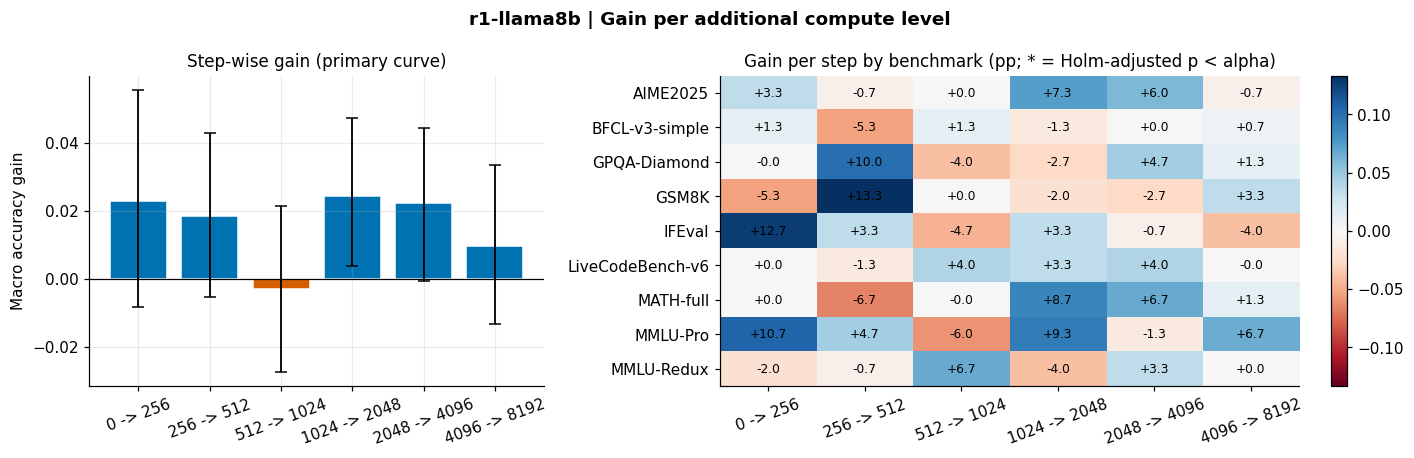

**Observed.** The first step (0 -> 256) adds +2.3 pp [-0.8 pp, +5.6 pp]; the last step (4096 -> 8192) adds +1.0 pp [-1.3 pp, +3.3 pp]. 9 of 9 benchmark(s) show a decrease in at least one step (point estimates; may be noise for small benchmarks).

**How to read.** Shrinking gains whose intervals increasingly include zero are consistent with diminishing returns; overlapping intervals for the first and last step do not by themselves show the gains are equal.

In [116]:
steps = []
for j in range(L - 1):
    dl, lo, hi = m_primary.diff(j, j + 1)
    steps.append({"step": f"{LV[j]} -> {LV[j + 1]}", "gain": dl, "ci_low": lo, "ci_high": hi, "p": m_primary.p(j, j + 1)})
step_tbl = pd.DataFrame(steps).set_index("step")
step_tbl["p_holm"] = holm(step_tbl["p"].values)
step_tbl["verdict"] = [verdict_p(a, b) for a, b in zip(step_tbl["gain"], step_tbl["p_holm"])]
total_gain = m_primary.point[-1] - m_primary.point[0]
step_tbl["share_of_total_gain"] = step_tbl["gain"] / total_gain if total_gain > 0 else np.nan
display(step_tbl)
save_table(step_tbl, "08_diminishing_returns")

M = np.zeros((len(sel), L - 1))
P = np.zeros_like(M)
for r, i in enumerate(sel):
    for j in range(L - 1):
        bd = PRIMARY.boot[:, i, vi, j + 1] - PRIMARY.boot[:, i, vi, j]
        M[r, j] = PRIMARY.point[i, vi, j + 1] - PRIMARY.point[i, vi, j]
        P[r, j] = boot_p(bd)
S = holm(P) < ALPHA

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
g = step_tbl["gain"].values
ax.bar(range(L - 1), g, color=[PALETTE[0] if x >= 0 else PALETTE[3] for x in g], edgecolor="white")
ax.errorbar(range(L - 1), g, yerr=[g - step_tbl.ci_low.values, step_tbl.ci_high.values - g], fmt="none", ecolor="black", capsize=4, lw=1.2)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(L - 1))
ax.set_xticklabels(step_tbl.index, rotation=20)
ax.set_ylabel("Macro accuracy gain")
ax.set_title("Step-wise gain (primary curve)")

vmax = max(np.nanmax(np.abs(M)), 1e-6)
ax = axes[1]
im = ax.imshow(M, cmap="RdBu", vmin=-vmax, vmax=vmax, aspect="auto")
for r in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, r, f"{100 * M[r, j]:+.1f}{'*' if S[r, j] else ''}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(L - 1))
ax.set_xticklabels(step_tbl.index, rotation=20)
ax.set_yticks(range(len(sel)))
ax.set_yticklabels([PRIMARY.cells[i][0] for i in sel])
ax.grid(False)
ax.set_title("Gain per step by benchmark (pp; * = Holm-adjusted p < alpha)")
fig.colorbar(im, ax=ax, fraction=0.04)
first, last_ = step_tbl.iloc[0], step_tbl.iloc[-1]
finish(fig, "08_diminishing_returns", "Gain per additional compute level", f"First step {pp(first.gain)}, last step {pp(last_.gain)}")

nonmono = int((M < 0).any(axis=1).sum())
md(f"**Observed.** The first step ({step_tbl.index[0]}) adds {pp(first.gain)} [{pp(first.ci_low)}, {pp(first.ci_high)}]; "
   f"the last step ({step_tbl.index[-1]}) adds {pp(last_.gain)} [{pp(last_.ci_low)}, {pp(last_.ci_high)}]. "
   f"{nonmono} of {len(sel)} benchmark(s) show a decrease in at least one step (point estimates; may be noise for small benchmarks).\n\n"
   "**How to read.** Shrinking gains whose intervals increasingly include zero are consistent with diminishing returns; overlapping intervals for the first and last step do not by themselves show the gains are equal.")

## 9. Truncation and response format: how much of the pattern is mechanical?

A sample can fail because the model *ran out of budget*, *never emitted the response marker*, or *emitted the marker but no answer*. These failures are mechanical rather than a matter of reasoning quality and can differ by level, so they must be known before any "over-thinking" interpretation. Assumed meaning of the flags (adjust if your pipeline differs):

* `was_truncated` — generation stopped at the token limit;
* `hit_response_marker` — the model emitted the delimiter separating thinking from the final answer;
* `hit_marker_empty_output` — the marker was emitted but the answer section is empty.

Each row gets **one** outcome (priority: truncated > marker-but-empty > no marker > complete). All rows stay in the accuracy numbers as graded; the "excluding truncated" curve is a *sensitivity analysis*, not a replacement.

Macro share of samples per outcome (equal benchmark weight, same questions at every level):


,Complete,Truncated
0,0.930,0.070
256,0.879,0.121
512,0.870,0.130
1024,0.850,0.150
2048,0.864,0.136
4096,0.917,0.083
8192,0.937,0.063


Sample counts per outcome:


outcome,Complete,Truncated
0,1255,95
256,1187,163
512,1174,176
1024,1148,202
2048,1167,183
4096,1238,112
8192,1265,85


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__09_truncation.csv
Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__09_truncation.png


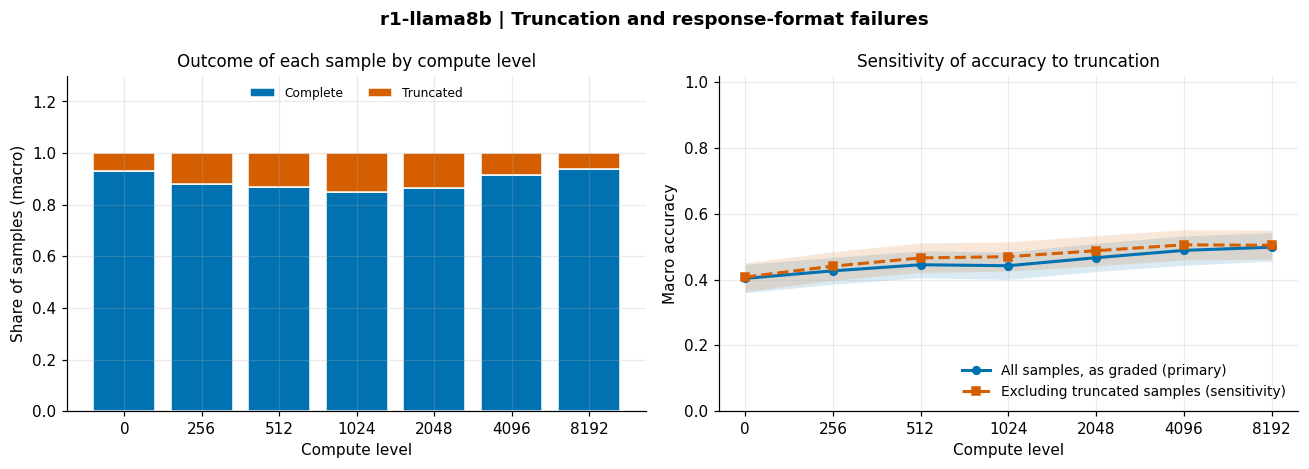

**Observed.** Truncated share: 7.0% at `0` -> 6.3% at `8192`. Excluding truncated samples, macro accuracy changes by +9.7 pp between the extreme levels (vs. +9.5 pp with all samples).

**How to read.** The truncation-excluded curve is **selection-biased**: truncated samples are usually the hardest questions, so excluding them flatters accuracy and the surviving questions differ by level. It shows how much of the shortfall is mechanical (budget exhaustion) rather than a reasoning failure. A decline at high compute together with a rising truncated share suggests a fixed output cap limits the top levels; a rising 'empty answer' share suggests the model spends its budget thinking and never answers.

In [117]:
flag_cols = ["was_truncated", "hit_response_marker", "hit_marker_empty_output"]
HAS_FLAGS = bool(d[flag_cols].notna().any().any())
out_curves, m_nt = {}, None
if not HAS_FLAGS:
    print("No truncation/format flags available; this section is skipped.")
else:
    tr, mk, me = d["was_truncated"], d["hit_response_marker"], d["hit_marker_empty_output"]
    cat = np.select([tr == 1, me == 1, mk == 0], ["Truncated", "Marker hit, empty answer", "No marker (not truncated)"], default="Complete")
    d["outcome"] = np.where(tr.isna() & mk.isna() & me.isna(), "Unknown", cat)
    outcome_names = [o for o in ["Complete", "Truncated", "Marker hit, empty answer", "No marker (not truncated)", "Unknown"] if (d.outcome == o).any()]
    for o in outcome_names:
        d[f"is_{o}"] = (d.outcome == o).astype(float)
    est_out = estimate(d, [f"is_{o}" for o in outcome_names], ["benchmark"], balanced=True)
    out_curves = {o: macro(est_out, f"is_{o}") for o in outcome_names}
    out_tbl = pd.DataFrame({o: c.point for o, c in out_curves.items()}, index=LV)
    print("Macro share of samples per outcome (equal benchmark weight, same questions at every level):")
    display(out_tbl)
    print("Sample counts per outcome:")
    display(pd.crosstab(d["compute_level"], d["outcome"]).reindex(LEVELS).set_axis(LV, axis=0))
    save_table(out_tbl, "09_truncation")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    colors = {"Complete": PALETTE[0], "Truncated": PALETTE[3], "Marker hit, empty answer": PALETTE[1], "No marker (not truncated)": PALETTE[4], "Unknown": "#999999"}
    ax, bottom = axes[0], np.zeros(L)
    for o in outcome_names:
        v = np.nan_to_num(out_curves[o].point)
        ax.bar(X, v, bottom=bottom, color=colors[o], label=o, edgecolor="white")
        bottom += v
    level_axis(ax)
    ax.set_ylabel("Share of samples (macro)")
    ax.set_ylim(0, 1.3)
    ax.set_title("Outcome of each sample by compute level")
    ax.legend(fontsize=8, loc="upper center", ncol=2)

    ax = axes[1]
    draw(ax, m_primary.point, m_primary.lo, m_primary.hi, color=PALETTE[0], label="All samples, as graded (primary)")
    est_nt = estimate(d[d.was_truncated != 1], ["correct"], ["benchmark"], balanced=False)
    m_nt = macro(est_nt, "correct") if est_nt is not None else None
    if m_nt is not None:
        draw(ax, m_nt.point, m_nt.lo, m_nt.hi, color=PALETTE[3], ls="--", marker="s", label="Excluding truncated samples (sensitivity)")
    level_axis(ax)
    ax.set_ylabel("Macro accuracy")
    ax.set_ylim(0, 1.02)
    ax.set_title("Sensitivity of accuracy to truncation")
    ax.legend(loc="lower right")
    t = out_curves.get("Truncated")
    finish(fig, "09_truncation", "Truncation and response-format failures",
           f"Truncated share {pct(t.point[0])} -> {pct(t.point[-1])}" if t is not None else "Response-format failures by level")

    parts = []
    if t is not None:
        parts.append(f"Truncated share: {pct(t.point[0])} at `{LV[0]}` -> {pct(t.point[-1])} at `{LV[-1]}`.")
    if m_nt is not None:
        parts.append(f"Excluding truncated samples, macro accuracy changes by {pp(m_nt.point[-1] - m_nt.point[0])} between the extreme levels (vs. {pp(m_primary.point[-1] - m_primary.point[0])} with all samples).")
    for o in [o for o in outcome_names if o in ("Marker hit, empty answer", "No marker (not truncated)")]:
        parts.append(f"'{o}': {pct(out_curves[o].point[0])} -> {pct(out_curves[o].point[-1])}.")
    md("**Observed.** " + " ".join(parts) + "\n\n"
       "**How to read.** The truncation-excluded curve is **selection-biased**: truncated samples are usually the hardest questions, so excluding them flatters accuracy and the surviving questions differ by level. "
       "It shows how much of the shortfall is mechanical (budget exhaustion) rather than a reasoning failure. A decline at high compute together with a rising truncated share suggests a fixed output cap limits the top levels; "
       "a rising 'empty answer' share suggests the model spends its budget thinking and never answers.")

## 10. Think longer or sample more? Repeated samples and pass@k

Multiple samples per question show *how* accuracy changes with compute:

* **Consistency:** the share of questions that are always right, always wrong or mixed. Gains can come from turning "always wrong" into "sometimes right", or "mixed" into reliable.
* **pass@k:** the probability that at least one of *k* samples is correct (unbiased estimator from `n` samples with `c` correct: `1 - C(n-c, k) / C(n, k)`). It is an **oracle** metric (perfect verifier), hence an upper bound for practical schemes such as majority voting.
* **Equal-token view:** pass@k at low compute costs about *k* times the tokens of one sample; plotting pass@k against total tokens compares "think longer" with "sample more" at similar cost.

Samples per question-level cell: min 5, median 5, max 5.


,all_correct,mixed,all_wrong
0,0.256,0.333,0.411
256,0.244,0.381,0.374
512,0.248,0.400,0.352
1024,0.237,0.411,0.352
2048,0.278,0.393,0.330
4096,0.304,0.370,0.326
8192,0.315,0.374,0.311


pass@k uses question-level cells with >= 5 samples: 1,890 of 1,890. k evaluated: [1, 2, 4, 5]


,pass@1,pass@2,pass@4,pass@5
0,0.404,0.488,0.568,0.589
256,0.427,0.520,0.602,0.626
512,0.445,0.548,0.629,0.648
1024,0.442,0.547,0.628,0.648
2048,0.467,0.562,0.645,0.670
4096,0.489,0.583,0.657,0.674
8192,0.499,0.594,0.673,0.689


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__10_repeated_samples.csv
Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__10_repeated_samples.png


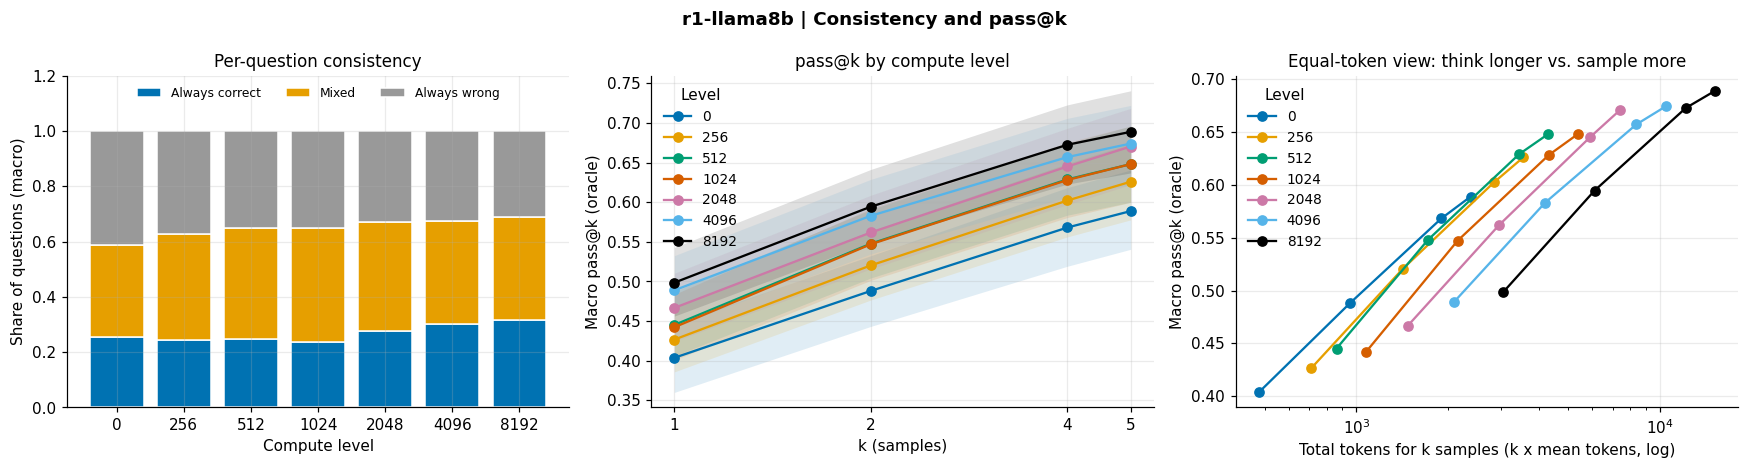

**Observed.** Macro pass@1 changes by +9.5 pp between `0` and `8192`, whereas pass@5 changes by +10.0 pp. The share of *always wrong* questions goes from 41.1% to 31.1%; *mixed* questions from 33.3% to 37.4%.

**How to read.** If pass@k at low compute already reaches the high-compute pass@1, sampling can replace deeper reasoning *when a verifier exists*. A higher pass@k at equal tokens in the right panel favours sampling; the reverse favours deeper thinking. Samples are assumed independent given the question, and token cost is approximated as k x the mean tokens per sample.

In [118]:
qcell = d.groupby(["benchmark", "question_id", "compute_level"])["correct"].agg(acc_q="mean", n_s="count").reset_index()
HAS_MULTI, pk, ks, cons = False, {}, [], {}
if (qcell.n_s >= 2).mean() < 0.5:
    print("Fewer than half of the question-level cells have >= 2 samples: consistency and pass@k are skipped.")
else:
    HAS_MULTI = True
    print(f"Samples per question-level cell: min {qcell.n_s.min()}, median {qcell.n_s.median():.0f}, max {qcell.n_s.max()}.")
    cs = qcell[qcell.n_s >= 2].copy()
    cs["all_correct"] = (cs.acc_q == 1).astype(float)
    cs["all_wrong"] = (cs.acc_q == 0).astype(float)
    cs["mixed"] = 1.0 - cs.all_correct - cs.all_wrong
    est_cs = estimate(cs, ["all_correct", "mixed", "all_wrong"], ["benchmark"], balanced=True)
    cons = {k: macro(est_cs, k, full_only=False) for k in ["all_correct", "mixed", "all_wrong"]}
    cons_tbl = pd.DataFrame({k: v.point for k, v in cons.items()}, index=LV)
    display(cons_tbl)

    K = min(8, int(qcell.n_s.mode().iloc[0]))
    ks = sorted({k for k in (1, 2, 4, 8) if k <= K} | {K})
    sub = qcell[qcell.n_s >= K].copy()
    print(f"pass@k uses question-level cells with >= {K} samples: {len(sub):,} of {len(qcell):,}. k evaluated: {ks}")
    c_ok, n_s = (sub.acc_q * sub.n_s).round().astype(int).values, sub.n_s.values
    for k in ks:
        sub[f"pass@{k}"] = [1 - math.comb(n - c, k) / math.comb(n, k) for n, c in zip(n_s, c_ok)]
    est_pk = estimate(sub, [f"pass@{k}" for k in ks], ["benchmark"], balanced=True)
    pk = {k: macro(est_pk, f"pass@{k}") for k in ks} if est_pk is not None else {}
    if pk:
        pk_tbl = pd.DataFrame({f"pass@{k}": pk[k].point for k in ks}, index=LV)
        display(pk_tbl)
        save_table(pd.concat([cons_tbl, pk_tbl], axis=1), "10_repeated_samples")

if HAS_MULTI and pk:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    ax, bottom = axes[0], np.zeros(L)
    for name, color, label in [("all_correct", PALETTE[0], "Always correct"), ("mixed", PALETTE[1], "Mixed"), ("all_wrong", "#999999", "Always wrong")]:
        ax.bar(X, cons[name].point, bottom=bottom, color=color, label=label, edgecolor="white")
        bottom += cons[name].point
    level_axis(ax)
    ax.set_ylabel("Share of questions (macro)")
    ax.set_title("Per-question consistency")
    ax.set_ylim(0, 1.2)
    ax.legend(loc="upper center", ncol=3, fontsize=8)

    ax = axes[1]
    for li, lv in enumerate(LV):
        pts, lo_, hi_ = (np.array([getattr(pk[k], a)[li] if a != "point" else pk[k].point[li] for k in ks]) for a in ("point", "lo", "hi"))
        ax.plot(ks, pts, marker="o", color=PALETTE[li % len(PALETTE)], label=lv)
        ax.fill_between(ks, lo_, hi_, color=PALETTE[li % len(PALETTE)], alpha=0.12, lw=0)
    ax.set_xscale("log", base=2)
    ax.set_xticks(ks)
    ax.set_xticklabels(ks)
    ax.set_xlabel("k (samples)")
    ax.set_ylabel("Macro pass@k (oracle)")
    ax.set_title("pass@k by compute level")
    ax.legend(title="Level")

    ax = axes[2]
    if tok is not None:
        for li, lv in enumerate(LV):
            ax.plot([k * tok.point[li] for k in ks], [pk[k].point[li] for k in ks], marker="o", color=PALETTE[li % len(PALETTE)], label=lv)
        ax.set_xscale("log")
        ax.set_xlabel("Total tokens for k samples (k x mean tokens, log)")
        ax.set_ylabel("Macro pass@k (oracle)")
        ax.set_title("Equal-token view: think longer vs. sample more")
        ax.legend(title="Level")
    else:
        ax.axis("off")
    gap1, gapK = pk[1].point[-1] - pk[1].point[0], pk[ks[-1]].point[-1] - pk[ks[-1]].point[0]
    finish(fig, "10_repeated_samples", "Consistency and pass@k", f"pass@1 {pp(gap1)} vs. pass@{ks[-1]} {pp(gapK)} between {LV[0]} and {LV[-1]}")
    md(f"**Observed.** Macro pass@1 changes by {pp(gap1)} between `{LV[0]}` and `{LV[-1]}`, whereas pass@{ks[-1]} changes by {pp(gapK)}. "
       f"The share of *always wrong* questions goes from {pct(cons['all_wrong'].point[0])} to {pct(cons['all_wrong'].point[-1])}; *mixed* questions from {pct(cons['mixed'].point[0])} to {pct(cons['mixed'].point[-1])}.\n\n"
       "**How to read.** If pass@k at low compute already reaches the high-compute pass@1, sampling can replace deeper reasoning *when a verifier exists*. A higher pass@k at equal tokens in the right panel favours sampling; the reverse favours deeper thinking. "
       "Samples are assumed independent given the question, and token cost is approximated as k x the mean tokens per sample.")

## 11. Cost: latency, tokens per correct answer and accuracy per 1,000 tokens

Accuracy is related to what it costs. All quantities use the same bootstrap replicates, so ratios are internally consistent.

* **Latency** is a macro mean per sample (same questions at every level); ratios to the lowest level are reported because absolute seconds depend on hardware. *Assumption:* `latency_s` is end-to-end wall-clock time per sample; with batching or concurrency it also reflects queueing, which the data cannot reveal.
* **Tokens (seconds) per correct answer** = macro mean tokens (latency) / macro accuracy; lower is more efficient.
* **Marginal return** = accuracy gain per additional 1,000 tokens (or second) between adjacent levels. The ratio is unstable when the token increase is close to zero, so `denominator_ok` flags steps whose increase is clearly positive.

,macro_mean_s,ci_low,ci_high,ratio_vs_lowest,ratio_ci_low,ratio_ci_high
0,47.819,44.785,50.768,1.000,1.000,1.000
256,67.710,63.613,72.226,1.416,1.336,1.504
512,75.189,71.447,78.885,1.572,1.494,1.657
1024,94.417,90.352,98.545,1.974,1.868,2.096
2048,138.949,132.522,145.660,2.906,2.739,3.104
4096,218.279,206.610,229.957,4.565,4.296,4.869
8192,336.571,312.130,362.569,7.038,6.530,7.619


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__11_latency.csv
Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__11_latency.png


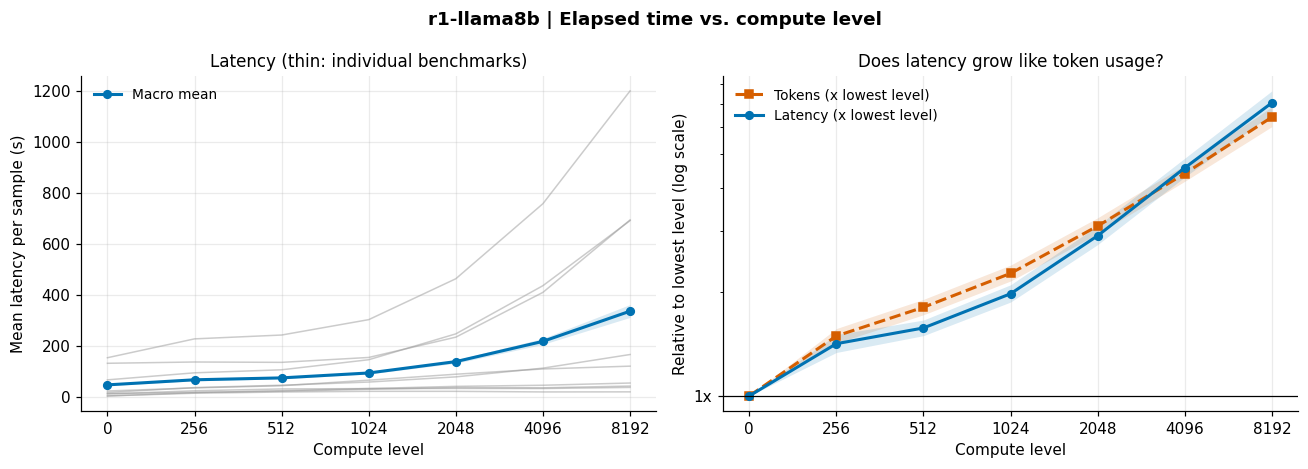

**Observed.** Macro mean latency rises from 47.8 s at `0` to 336.6 s at `8192` (7.0x; CI 6.5-7.6x), while tokens grow 6.4x. Similar growth of both suggests latency is driven mainly by the number of generated tokens (**hypothesis**; hardware and batching are not recorded).

In [119]:
if lat is None:
    print("No usable latency_s values; latency analysis is skipped.")
else:
    lat_ratio = Curve(lat.point / lat.point[0], lat.boot / lat.boot[:, :1])
    tok_ratio_c = Curve(tok.point / tok.point[0], tok.boot / tok.boot[:, :1]) if tok is not None else None
    lat_tbl = pd.DataFrame({"macro_mean_s": lat.point, "ci_low": lat.lo, "ci_high": lat.hi,
                            "ratio_vs_lowest": lat_ratio.point, "ratio_ci_low": lat_ratio.lo, "ratio_ci_high": lat_ratio.hi}, index=LV)
    display(lat_tbl)
    save_table(lat_tbl, "11_latency")

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    ax = axes[0]
    for c in lat.cells:
        ax.plot(X, PRIMARY.point[PRIMARY.cells.index(c), PRIMARY.values.index("latency_s")], color="#999999", alpha=0.5, lw=1)
    draw(ax, lat.point, lat.lo, lat.hi, color=PALETTE[0], label="Macro mean")
    level_axis(ax)
    ax.set_ylabel("Mean latency per sample (s)")
    ax.set_title("Latency (thin: individual benchmarks)")
    ax.legend()
    ax = axes[1]
    if tok_ratio_c is not None:
        draw(ax, tok_ratio_c.point, tok_ratio_c.lo, tok_ratio_c.hi, color=PALETTE[3], ls="--", marker="s", label="Tokens (x lowest level)")
    draw(ax, lat_ratio.point, lat_ratio.lo, lat_ratio.hi, color=PALETTE[0], label="Latency (x lowest level)")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}x"))
    ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    ax.axhline(1, color="black", lw=0.8)
    level_axis(ax)
    ax.set_ylabel("Relative to lowest level (log scale)")
    ax.set_title("Does latency grow like token usage?")
    ax.legend()
    finish(fig, "11_latency", "Elapsed time vs. compute level",
           f"Latency grows {lat_ratio.point[-1]:.1f}x" + (f" while tokens grow {tok_ratio_c.point[-1]:.1f}x" if tok_ratio_c is not None else ""))
    md(f"**Observed.** Macro mean latency rises from {lat.point[0]:.1f} s at `{LV[0]}` to {lat.point[-1]:.1f} s at `{LV[-1]}` ({lat_ratio.point[-1]:.1f}x; CI {lat_ratio.lo[-1]:.1f}-{lat_ratio.hi[-1]:.1f}x)"
       + (f", while tokens grow {tok_ratio_c.point[-1]:.1f}x" if tok_ratio_c is not None else "")
       + ". Similar growth of both suggests latency is driven mainly by the number of generated tokens (**hypothesis**; hardware and batching are not recorded).")

,accuracy,mean_tokens,tokens_ci_low,tokens_ci_high,tokens_per_correct,tpc_ci_low,tpc_ci_high,thinking_share,seconds_per_correct,spc_ci_low,spc_ci_high
0,0.404,476.593,448.531,505.099,"1,180.550","1,034.913","1,347.348",0.000,118.450,104.191,135.275
256,0.427,710.423,678.261,745.662,"1,665.054","1,487.413","1,870.229",0.344,158.696,140.481,178.978
512,0.445,860.067,829.033,893.544,"1,931.930","1,747.063","2,143.965",0.520,168.894,151.439,188.247
1024,0.442,"1,077.768","1,043.125","1,112.926","2,437.164","2,194.043","2,710.252",0.689,213.507,192.026,238.136
2048,0.467,"1,476.956","1,423.989","1,530.974","3,164.906","2,843.635","3,506.266",0.801,297.749,268.755,331.938
4096,0.489,"2,094.257","2,002.827","2,187.986","4,283.708","3,855.962","4,777.575",0.869,446.479,400.913,501.777
8192,0.499,"3,049.722","2,868.364","3,240.916","6,117.571","5,464.114","6,900.959",0.913,675.143,595.836,765.681


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__11_efficiency.csv
Marginal return between adjacent levels (pp = percentage points of accuracy):


,d_acc,d_acc_lo,d_acc_hi,d_tokens,pp_per_1k_tokens,per1k_lo,per1k_hi,denominator_ok,d_seconds,pp_per_second
step,,,,,,,,,,
0 -> 256,0.023,-0.008,0.056,233.830,9.820,-3.525,24.356,True,19.892,0.115
256 -> 512,0.019,-0.005,0.043,149.644,12.375,-3.828,30.099,True,7.479,0.248
512 -> 1024,-0.003,-0.027,0.021,217.701,-1.361,-12.818,9.755,True,19.228,-0.015
1024 -> 2048,0.024,0.004,0.047,399.188,6.124,0.944,11.837,True,44.532,0.055
2048 -> 4096,0.022,-0.001,0.044,617.301,3.600,-0.118,7.230,True,79.329,0.028
4096 -> 8192,0.010,-0.013,0.033,955.465,1.008,-1.357,3.622,True,118.292,0.008


Saved figure: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__11_efficiency.png


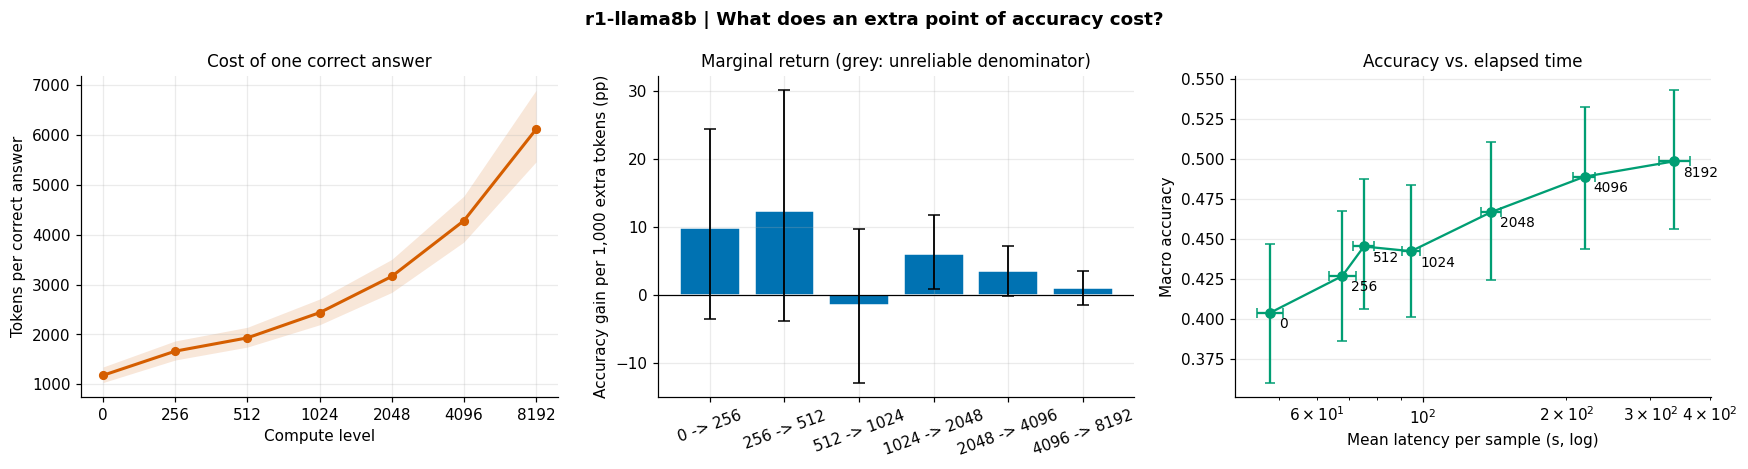

**Observed.** Mean tokens grow 6.4x from `0` to `8192` while macro accuracy changes by +9.5 pp. Tokens per correct answer are lowest at `0` (1,181) and 6,118 at `8192`. The last step costs 955 extra tokens for +1.0 pp.

**How to read.** Points moving right with little upward movement indicate poor marginal efficiency. The best operating point lies where tokens per correct answer is minimal or where the gain per 1,000 tokens falls below a cost threshold; that threshold is a business decision, not a statistical one.

In [120]:
acc = m_primary
eff = pd.DataFrame({"accuracy": acc.point}, index=LV)
if tok is not None:
    tpc = Curve(tok.point / acc.point, tok.boot / acc.boot)
    eff["mean_tokens"], eff["tokens_ci_low"], eff["tokens_ci_high"] = tok.point, tok.lo, tok.hi
    eff["tokens_per_correct"], eff["tpc_ci_low"], eff["tpc_ci_high"] = tpc.point, tpc.lo, tpc.hi
if think is not None and tok is not None:
    eff["thinking_share"] = think.point / tok.point
if lat is not None:
    lpc = Curve(lat.point / acc.point, lat.boot / acc.boot)
    eff["seconds_per_correct"], eff["spc_ci_low"], eff["spc_ci_high"] = lpc.point, lpc.lo, lpc.hi
display(eff)
save_table(eff, "11_efficiency")

mr = []
for j in range(L - 1):
    r = {"step": f"{LV[j]} -> {LV[j + 1]}"}
    da, a_lo, a_hi = acc.diff(j, j + 1)
    r.update(d_acc=da, d_acc_lo=a_lo, d_acc_hi=a_hi)
    if tok is not None:
        dt_, t_lo, t_hi = tok.diff(j, j + 1)
        lo, hi = _ci((acc.boot[:, j + 1] - acc.boot[:, j]) / ((tok.boot[:, j + 1] - tok.boot[:, j]) / 1000))
        r.update(d_tokens=dt_, pp_per_1k_tokens=100 * da / (dt_ / 1000) if dt_ else np.nan, per1k_lo=100 * lo, per1k_hi=100 * hi, denominator_ok=bool(t_lo > 0 or t_hi < 0))
    if lat is not None:
        dl_ = lat.diff(j, j + 1)[0]
        r.update(d_seconds=dl_, pp_per_second=100 * da / dl_ if dl_ else np.nan)
    mr.append(r)
mr_tbl = pd.DataFrame(mr).set_index("step")
print("Marginal return between adjacent levels (pp = percentage points of accuracy):")
display(mr_tbl)
save_table(mr_tbl, "11_marginal_return")
if "denominator_ok" in mr_tbl and not mr_tbl["denominator_ok"].all():
    print("NOTE: for steps with denominator_ok=False the token increase is not clearly positive; the ratio is unreliable.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ax = axes[0]
if tok is not None:
    draw(ax, tpc.point, tpc.lo, tpc.hi, color=PALETTE[3], label="Tokens per correct answer")
    level_axis(ax)
    ax.set_ylabel("Tokens per correct answer")
ax.set_title("Cost of one correct answer")
ax = axes[1]
if tok is not None:
    v_ = mr_tbl["pp_per_1k_tokens"].values
    ax.bar(range(L - 1), v_, color=[PALETTE[0] if ok else "#999999" for ok in mr_tbl["denominator_ok"]], edgecolor="white")
    ax.errorbar(range(L - 1), v_, yerr=[v_ - mr_tbl.per1k_lo.values, mr_tbl.per1k_hi.values - v_], fmt="none", ecolor="black", capsize=4, lw=1.2)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(range(L - 1))
    ax.set_xticklabels(mr_tbl.index, rotation=20)
    ax.set_ylabel("Accuracy gain per 1,000 extra tokens (pp)")
ax.set_title("Marginal return (grey: unreliable denominator)")
ax = axes[2]
if lat is not None:
    ax.errorbar(lat.point, acc.point, yerr=[acc.point - acc.lo, acc.hi - acc.point], xerr=[lat.point - lat.lo, lat.hi - lat.point], fmt="o-", color=PALETTE[2], capsize=3, lw=1.5)
    for x, y, lv in zip(lat.point, acc.point, LV):
        ax.annotate(lv, (x, y), textcoords="offset points", xytext=(6, -10), fontsize=9)
    ax.set_xscale("log")
ax.set_xlabel("Mean latency per sample (s, log)")
ax.set_ylabel("Macro accuracy")
ax.set_title("Accuracy vs. elapsed time")
take = f"Tokens per correct answer: {tpc.point[0]:,.0f} -> {tpc.point[-1]:,.0f}" if tok is not None else "Cost of accuracy"
finish(fig, "11_efficiency", "What does an extra point of accuracy cost?", take)

if tok is not None:
    best = int(np.nanargmin(tpc.point))
    md(f"**Observed.** Mean tokens grow {tok.point[-1] / tok.point[0]:.1f}x from `{LV[0]}` to `{LV[-1]}` while macro accuracy changes by {pp(acc.point[-1] - acc.point[0])}. "
       f"Tokens per correct answer are lowest at `{LV[best]}` ({tpc.point[best]:,.0f}) and {tpc.point[-1]:,.0f} at `{LV[-1]}`. The last step costs {mr_tbl.d_tokens.iloc[-1]:,.0f} extra tokens for {pp(mr_tbl.d_acc.iloc[-1])}.\n\n"
       "**How to read.** Points moving right with little upward movement indicate poor marginal efficiency. The best operating point lies where tokens per correct answer is minimal or where the gain per 1,000 tokens falls below a cost threshold; that threshold is a business decision, not a statistical one.")

## 12. Recommendation and limitations

The summary below is **generated from the results above**: it states observed quantities with their uncertainty and keeps hypotheses separate. The operating-point table puts accuracy and cost side by side; the suggested level is the **lowest level that is not credibly worse than the best level** (paired interval of the accuracy difference). "Not credibly worse" is not "equal", and the final choice depends on how much cost is acceptable.

In [121]:
best_i = int(np.argmax(m_primary.point))
rows = []
for j in range(L):
    dl, lo, hi = m_primary.diff(best_i, j) if j != best_i else (0.0, 0.0, 0.0)
    r = {"level": LV[j], "accuracy": m_primary.point[j], "vs_best_pp": 100 * dl, "vs_best_ci_low": 100 * lo, "vs_best_ci_high": 100 * hi,
         "credibly_worse_than_best": bool(hi < 0), "normalised_gain": m_ng.point[j]}
    if tok is not None:
        r["tokens_per_correct"] = tpc.point[j]
    if lat is not None:
        r["latency_x_lowest"] = lat_ratio.point[j]
        r["seconds_per_correct"] = lpc.point[j]
    if m_trunc is not None:
        r["truncated_share"] = m_trunc.point[j]
    rows.append(r)
reco_tbl = pd.DataFrame(rows).set_index("level")
reco_level = reco_tbl.index[~reco_tbl["credibly_worse_than_best"]][0]
display(reco_tbl)
save_table(reco_tbl, "12_operating_points")

lines = []
a0, a1 = m_primary.point[0], m_primary.point[-1]
dm, dm_lo, dm_hi = m_primary.diff(0, -1)
n_q_primary = int(sum(PRIMARY.nq[PRIMARY.cells.index(c)] for c in m_primary.cells))
lines.append(f"**Data and design.** {len(d):,} graded samples, {d.groupby(['benchmark', 'question_id']).ngroups:,} questions, {d.benchmark.nunique()} benchmarks, {L} compute levels ({' < '.join(LV)}). "
             f"The primary estimate uses {len(sel)} benchmark(s) and {n_q_primary:,} questions observed at every level."
             + (f" Excluded for incomplete coverage: {partial_bench}." if partial_bench else ""))
if real is not None:
    lines.append(f"**Realised compute.** The average benchmark uses {real.point[-1]:.1f}x the `{TOK}` at `{LV[-1]}` vs. `{LV[REF_I]}`; "
                 + ("every step clearly increases token use." if (real_steps["verdict"] == "more tokens").all()
                    else f"steps without a clear token increase: {real_steps.index[real_steps['verdict'] != 'more tokens'].tolist()}."))
lines.append(f"**Headline.** Macro accuracy {pct(a0)} -> {pct(a1)}: {pp(dm)} [{pp(dm_lo)}, {pp(dm_hi)}], *{sig(dm_lo, dm_hi)}*; normalised gain {m_ng.point[-1]:.0%}. Highest point estimate at `{LV[best_i]}`.")
v = bench_tbl["verdict"].value_counts()
lines.append(f"**Per benchmark (Holm-adjusted).** Increase: {v.get('increase', 0)}, no clear change: {v.get('no clear change', 0)}, decrease: {v.get('decrease', 0)}.")
if len(tt_tbl):
    lines.append("**Task types.** " + "; ".join(f"{t}: {pp(r.delta)} (normalised {r.norm_gain:.0%})" for t, r in tt_tbl.iterrows())
                 + (f"; interaction p = {p_int_tt:.3g}" if not np.isnan(p_int_tt) else "") + ".")
if len(dt_tbl):
    lines.append("**Difficulty.** " + "; ".join(f"{t}: {pp(r.delta)}" for t, r in dt_tbl.iterrows()) + ".")
lines.append("**Diminishing returns.** " + ", ".join(f"{i}: {pp(r.gain)}" for i, r in step_tbl.iterrows()) + ".")
if out_curves.get("Truncated") is not None:
    t_ = out_curves["Truncated"]
    lines.append(f"**Truncation.** Truncated share {pct(t_.point[0])} -> {pct(t_.point[-1])}."
                 + (f" Excluding truncated samples the change is {pp(m_nt.point[-1] - m_nt.point[0])}." if m_nt is not None else ""))
if HAS_MULTI and pk:
    lines.append(f"**Repeated samples.** pass@1 change {pp(pk[1].point[-1] - pk[1].point[0])}; pass@{ks[-1]} change {pp(pk[ks[-1]].point[-1] - pk[ks[-1]].point[0])}.")
if lat is not None:
    lines.append(f"**Latency.** Grows {lat_ratio.point[-1]:.1f}x from `{LV[0]}` to `{LV[-1]}`.")
if tok is not None:
    lines.append(f"**Cost.** Tokens grow {tok.point[-1] / tok.point[0]:.1f}x; tokens per correct answer {tpc.point[0]:,.0f} -> {tpc.point[-1]:,.0f} (minimum at `{LV[int(np.nanargmin(tpc.point))]}`).")
lines.append(f"**Suggested operating point.** `{reco_level}` is the lowest level not credibly worse than the best level (`{LV[best_i]}`).")
md("\n\n".join(f"- {x}" for x in lines))

summary = pd.DataFrame([{
    "benchmarks": len(sel), "questions": n_q_primary, "levels": " < ".join(LV),
    "acc_lowest": a0, "acc_highest": a1, "change_pp": 100 * dm, "ci_low_pp": 100 * dm_lo, "ci_high_pp": 100 * dm_hi, "normalised_gain": m_ng.point[-1],
    "token_ratio": real.point[-1] if real is not None else np.nan, "token_ratio_baseline": LV[REF_I], "latency_ratio": lat_ratio.point[-1] if lat is not None else np.nan,
    "tokens_per_correct_lowest": tpc.point[0] if tok is not None else np.nan, "tokens_per_correct_highest": tpc.point[-1] if tok is not None else np.nan,
    "truncated_share_highest": m_trunc.point[-1] if m_trunc is not None else np.nan,
    "best_level": LV[best_i], "suggested_level": reco_level}], index=[MODEL_NAME])
save_table(summary, "summary")

,accuracy,vs_best_pp,vs_best_ci_low,vs_best_ci_high,credibly_worse_than_best,normalised_gain,tokens_per_correct,latency_x_lowest,seconds_per_correct,truncated_share
level,,,,,,,,,,
0,0.404,-9.481,-13.259,-5.778,True,0.000,"1,180.550",1.000,118.450,0.070
256,0.427,-7.185,-10.370,-3.926,True,0.025,"1,665.054",1.416,158.696,0.121
512,0.445,-5.333,-8.520,-2.000,True,0.066,"1,931.930",1.572,168.894,0.130
1024,0.442,-5.630,-8.370,-2.961,True,0.068,"2,437.164",1.974,213.507,0.150
2048,0.467,-3.185,-5.481,-0.815,True,0.107,"3,164.906",2.906,297.749,0.136
4096,0.489,-0.963,-3.333,1.333,False,0.146,"4,283.708",4.565,446.479,0.083
8192,0.499,0.000,0.000,0.000,False,0.168,"6,117.571",7.038,675.143,0.063


Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__12_operating_points.csv


- **Data and design.** 9,450 graded samples, 270 questions, 9 benchmarks, 7 compute levels (0 < 256 < 512 < 1024 < 2048 < 4096 < 8192). The primary estimate uses 9 benchmark(s) and 270 questions observed at every level.

- **Realised compute.** The average benchmark uses 11.1x the `thinking_tokens` at `8192` vs. `256`; every step clearly increases token use.

- **Headline.** Macro accuracy 40.4% -> 49.9%: +9.5 pp [+5.8 pp, +13.3 pp], *increase*; normalised gain 17%. Highest point estimate at `8192`.

- **Per benchmark (Holm-adjusted).** Increase: 2, no clear change: 7, decrease: 0.

- **Task types.** MCQ: +12.2 pp (normalised 20%); Open-ended: +8.1 pp (normalised 15%); interaction p = 0.985.

- **Difficulty.** easy: +6.7 pp; medium: +10.2 pp; hard: +11.6 pp.

- **Diminishing returns.** 0 -> 256: +2.3 pp, 256 -> 512: +1.9 pp, 512 -> 1024: -0.3 pp, 1024 -> 2048: +2.4 pp, 2048 -> 4096: +2.2 pp, 4096 -> 8192: +1.0 pp.

- **Truncation.** Truncated share 7.0% -> 6.3%. Excluding truncated samples the change is +9.7 pp.

- **Repeated samples.** pass@1 change +9.5 pp; pass@5 change +10.0 pp.

- **Latency.** Grows 7.0x from `0` to `8192`.

- **Cost.** Tokens grow 6.4x; tokens per correct answer 1,181 -> 6,118 (minimum at `0`).

- **Suggested operating point.** `4096` is the lowest level not credibly worse than the best level (`8192`).

Saved table: ..\..\results\r1-llama8b\compute_level_analysis\r1-llama8b__summary.csv


### Limitations and how to read the evidence

* **Observational comparison.** Unless compute level was randomly assigned to identical questions, differences may reflect unrecorded differences between runs (hardware, date, prompt version, sampling settings). The same-question design removes *question* confounding, not run-level confounding.
* **Benchmarks are a fixed, non-random set.** Intervals reflect question sampling within benchmarks. Equal-weight macro-averaging answers "how does an average benchmark behave?"; a different weighting (e.g. by deployment relevance) answers a different question. Section 6 shows the sensitivity.
* **Incomplete coverage is excluded** from level-to-level comparisons. If excluded benchmarks or questions differ systematically, the primary curve may not generalise to them.
* **Normalised gain** is unstable for benchmarks already close to the ceiling at the lowest level (the denominator is floored); treat those values as indicative only.
* **Multiple comparisons.** Per-benchmark, per-step, per-type, per-tier and long-vs-short claims are Holm-adjusted within their family; other intervals are descriptive, so isolated "credible" results are leads, not confirmations.
* **Task types and difficulty.** Types with a single benchmark cannot be separated from that benchmark. Tiers are defined within each benchmark and are not comparable across them; tiers taken from the data itself (rather than benchmark metadata) are affected by regression to the mean unless `DIFFICULTY_SOURCE = "split_half"` is used.
* **Ordering of levels.** Levels are treated as ordered categories; if the spacing in real compute is unequal, step-wise "diminishing returns" is partly a spacing effect (Section 3b shows accuracy against realised effort, Section 11 per-token returns).
* **Latency** depends on hardware, batching and load, which are not in the data.
* **Length analyses (10, A)** are within-question associations, not causal effects. They use only informative questions, and the set of informative questions differs by level and benchmark. Truncated samples are mechanically long and wrong, hence the repeat without them.
* **pass@k** assumes a perfect verifier and independent samples; the equal-token comparison is an approximation.
* **Flags** (`was_truncated`, `hit_response_marker`, `hit_marker_empty_output`) follow the definitions stated in Section 9.
* **Grading noise.** Unreadable `is_correct` labels are handled according to `MISSING_CORRECT`; label errors in the benchmarks themselves are not assessed.
* **Suggested level** is a rule-based summary of statistical evidence, not a cost-benefit decision.

**Follow-ups** (only if the findings warrant them): re-run with a higher output-token cap if truncation is material at the top levels; add questions at levels with thin coverage; collect more samples per question if many cells in Section 11 are blank; test a cheap early-stopping or adaptive-compute rule if long traces were associated with failure.

## Appendix A. Several models

Everything above depends only on the parameters in the configuration cell, which is tagged `parameters`. To analyse several models, run the notebook once per model with [papermill](https://papermill.readthedocs.io), pointing all runs at the **same `SAVE_DIR`**:

```bash
papermill compute_level_analysis.ipynb runs/<model>.ipynb \
    -p DATA_PATH path/to/<model>_raw_results.csv -p MODEL_NAME <model> -p SAVE_DIR results/compute_level_analysis
```

Each run writes `<MODEL_NAME>__summary.csv`; the cell below collects all summaries found in `SAVE_DIR` into one comparison table and plot.

In [122]:
files = sorted(SAVE_PATH.glob("*__summary.csv"))
if len(files) < 2:
    print(f"{len(files)} model summary found in {SAVE_PATH}; run the notebook for at least two models to get a comparison.")
else:
    comp = pd.concat([pd.read_csv(f, index_col=0) for f in files])
    display(comp)
    comp.to_csv(SAVE_PATH / "model_comparison.csv")
    curves = {f.name.split("__")[0]: pd.read_csv(f.with_name(f.name.replace("__summary", "__03_headline")), index_col=0)
              for f in files if f.with_name(f.name.replace("__summary", "__03_headline")).exists()}
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for k, (m, c) in enumerate(curves.items()):
        axes[0].plot(range(len(c)), c["accuracy"], marker="o", color=PALETTE[k % len(PALETTE)], label=m)
        axes[1].plot(range(len(c)), 100 * c["normalised_gain"], marker="s", color=PALETTE[k % len(PALETTE)], label=m)
    longest = max(curves.values(), key=len)
    for ax, yl in zip(axes, ["Macro accuracy", "Normalised gain (% of headroom)"]):
        ax.set_xticks(range(len(longest)))
        ax.set_xticklabels(longest.index)
        ax.set_xlabel("Compute level")
        ax.set_ylabel(yl)
        ax.legend()
    fig.suptitle("Model comparison", fontweight="bold")
    fig.tight_layout()
    fig.savefig(SAVE_PATH / "model_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()

1 model summary found in ..\..\results\r1-llama8b\compute_level_analysis; run the notebook for at least two models to get a comparison.
